EDA (EXPLORATORY DATA ANALYSIS) OF SITES AND MONUMENTS



Feature engineering of the monuments dataset.


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import numpy as np
import seaborn as sns
import os
import json
import geoplot
import pysal
import re
from sklearn.feature_extraction.text import CountVectorizer
import sys
# import contextily as ctx
# sys.path.insert(0, '../ArchaeTron')
# from FileManager import data_saver

# from src.ArchaeTron.GeoDataHandler import TextEntitySearch

In [3]:
# Import classes from the main program 

# save_files = data_saver.DataSaver()


In [4]:
# Import the data

tuatha_nw_1600_mod = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/tuatha_nw_1600_mod.shp')

sites_nw_clean = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_clean.shp')
sites_nw_clean.columns


Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry'],
      dtype='object')

In [5]:
tuatha_nw_1600_mod.columns

Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'connection', 'chief_king', 'geometry'],
      dtype='object')

<Figure size 1000x800 with 0 Axes>

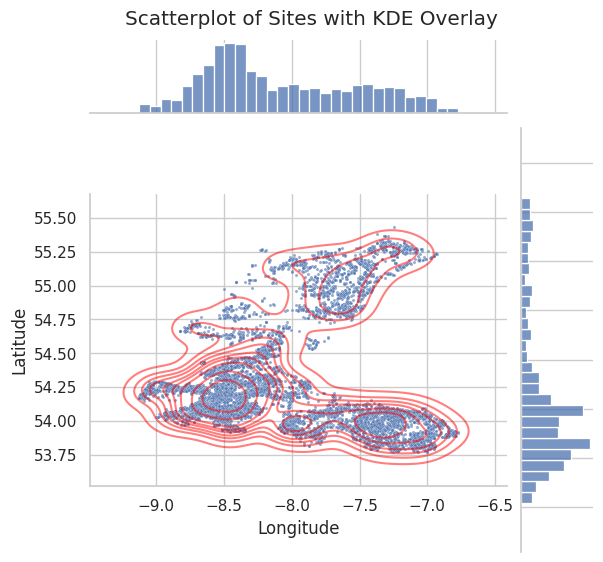

In [6]:
sns.set(style="whitegrid")  # Use a clean style
plt.figure(figsize=(10, 8))  # Adjust figure size

# Create scatterplot with KDE overlay
sns.jointplot(
    x="LONGITUDE", 
    y="LATITUDE", 
    data=sites_nw_clean, 
    kind="scatter", 
    s=5,  # Adjust marker size
    alpha=0.6,  # Add transparency
    marginal_kws=dict(bins=30, fill=True),  # Add marginal histograms
).plot_joint(sns.kdeplot, color="red", alpha=0.5)  # Add KDE overlay

# Add labels and title
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.suptitle("Scatterplot of Sites with KDE Overlay", y=1.02)  # Adjust title position
plt.gca().set_aspect('equal', adjustable='box')  # Set equal aspect ratio
plt.show()

CREATE A BUFFER FROM CENTRE OF EACH TERRITORY AND RETURN THE SITES WITHIN A CERTAIN DISTANCE


In [7]:
# Create a buffer from the centroid of each territory, this will be used to select sites within each territory
buffer_distance = 1800  # Set the buffer distance as needed

# Assign an ID to each territory
tuatha_nw_1600_mod['ID'] = range(len(tuatha_nw_1600_mod))

# Create a buffer from the centroid of each territory
buffer_df = gpd.GeoDataFrame({'geometry': tuatha_nw_1600_mod.centroid.buffer(buffer_distance), 'ID': tuatha_nw_1600_mod['ID']})

# Use a spatial join to match the monuments with the territories
monuments_in_buffer = gpd.sjoin(sites_nw_clean, buffer_df, how='inner', op='within')

# Count the number of unique MONUMENT_T in each buffer
unique_monuments = monuments_in_buffer.groupby('ID')['MONUMENT_T'].unique()
print(unique_monuments)


TypeError: sjoin() got an unexpected keyword argument 'op'

In [7]:
# Output the results to a text file
unique_monuments.to_csv('unique_monuments_buffer.txt', header=True)

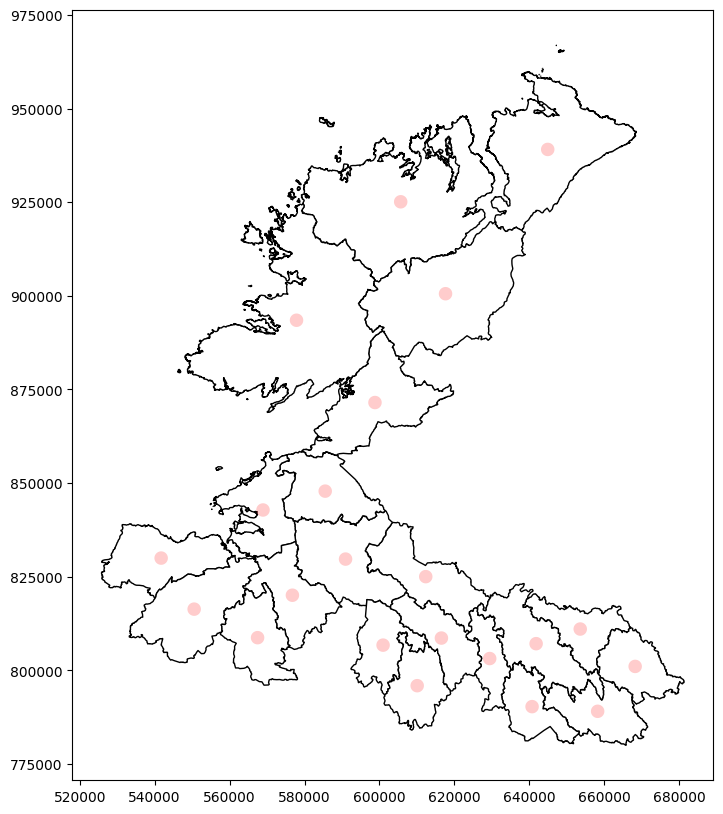

ValueError: Grouper and axis must be same length

In [8]:
#import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the territories
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black')

# Plot the buffers as transparent circles
buffer_df.plot(ax=ax, color='red', alpha=0.2)

plt.show()

# Count the number of unique MONUMENT_T in each buffer
unique_monuments = monuments_in_buffer.groupby(buffer_df.index)['MONUMENT_T'].nunique()
print(unique_monuments)

NameError: name 'unique_monuments' is not defined

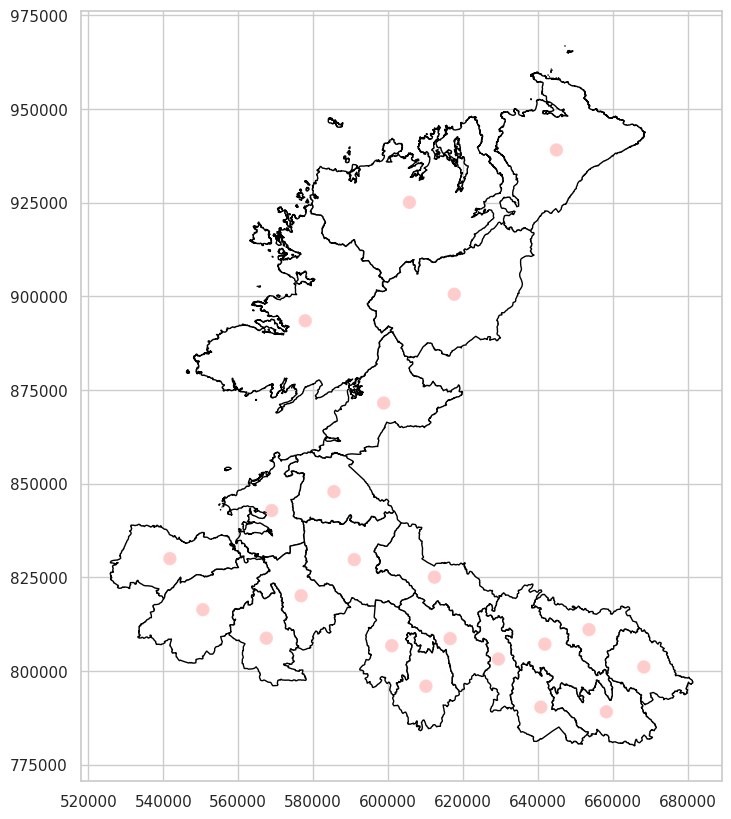

In [7]:
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the territories
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black')

# Plot the buffers as transparent circles
buffer_df.plot(ax=ax, color='red', alpha=0.2)

# Create a list to store the legend elements
legend_elements = []

# Loop through each territory and add a patch to the legend elements
for territory in tuatha_nw_1600_mod['ENGLISH'].unique():
    num_monuments = unique_monuments[territory] if territory in unique_monuments else 0
    legend_elements.append(mpatches.Patch(color='red', label=f'{territory}: {num_monuments}'))

# Add the legend to the plot
ax.legend(handles=legend_elements, loc='upper left')

plt.show()

/tmp/ipykernel_154560/1056033627.py:6: UserWarning: Only one of 'bins' and 'norm' arguments can be supplied, ignoring bins='log'
  hb = ax.hexbin(


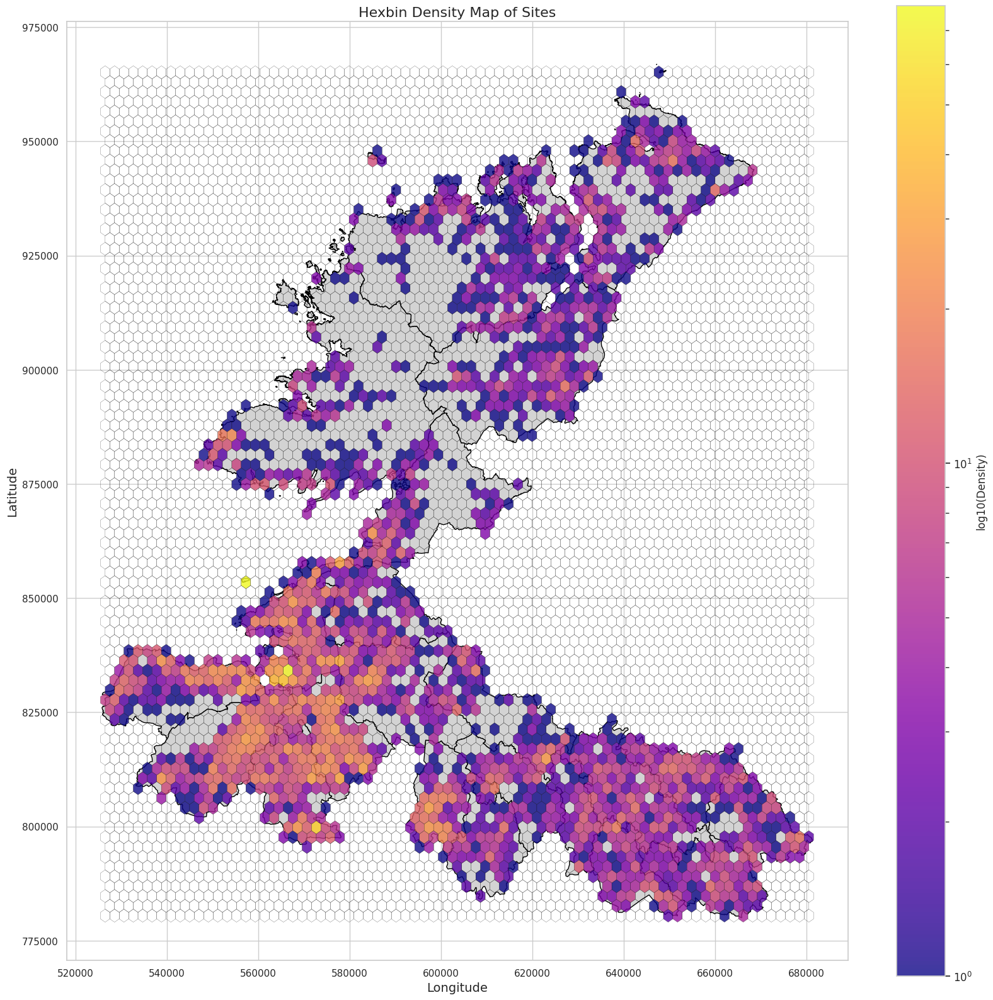

In [8]:
# Plot the basemap using tuatha_map
fig, ax = plt.subplots(figsize=(20, 20))
tuatha_nw_1600_mod.plot(ax=ax, color='lightgray', edgecolor='black')

# Create hexbin map for point densities
hb = ax.hexbin(
    sites_nw_clean['geometry'].x,
    sites_nw_clean['geometry'].y,
    gridsize=75,  # Increased gridsize for finer resolution
    bins='log',   # Apply logarithmic scale to color intensity
    cmap='plasma',  # Use a visually appealing colormap
    alpha=0.8,  # Set transparency
    edgecolors='black',  # Add borders to hexagons
    linewidths=0.2,  # Set border width
    norm=LogNorm(),  # Use logarithmic scale for color normalization
)

# Add colorbar
cb = plt.colorbar(hb, ax=ax, label='log10(Density)')
cb.ax.tick_params(labelsize=12)  # Adjust colorbar tick size

# Add labels, title, and set aspect ratio
ax.set_xlabel('Longitude', fontsize=14)
ax.set_ylabel('Latitude', fontsize=14)
ax.set_title('Hexbin Density Map of Sites', fontsize=16)
ax.set_aspect('equal', adjustable='box')  # Ensure equal aspect ratio

plt.show()



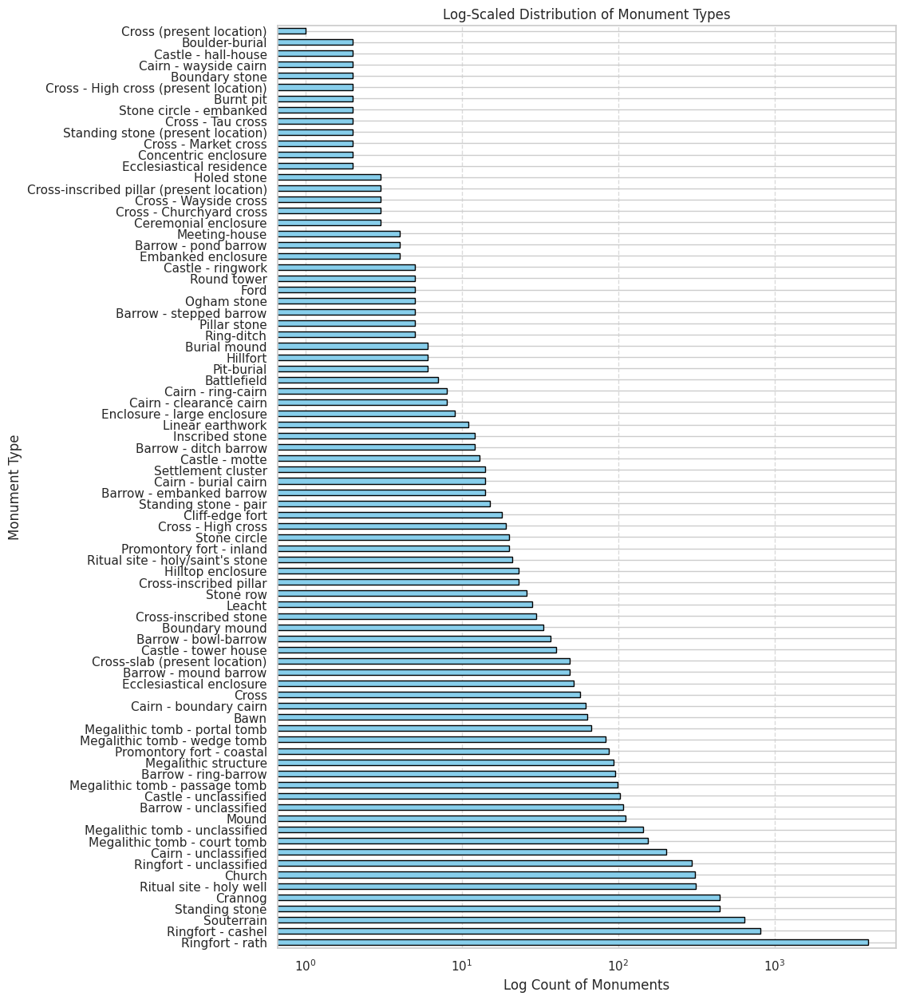

In [9]:
# List unique values in the sites_nw_clean['MONUMENT_T'] column
monument_counts = sites_nw_clean['MONUMENT_T'].value_counts()

# Plot the bar chart with a logarithmic scale
plt.figure(figsize=(10, 15))
monument_counts.plot(kind='barh', logx=True, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel("Log Count of Monuments")
plt.ylabel("Monument Type")
plt.title("Log-Scaled Distribution of Monument Types")
plt.grid(axis='x', linestyle='--', alpha=0.7)  # Optional: Add gridlines for better readability

plt.show()


In [ ]:
# Here we begin to tidy up the features in the MONUMENT_T column.
# Join Cairn - unclassified and Cairn - boundary cairn together
# sites_nw_clean['MONUMENT_T'] = sites_nw_clean['MONUMENT_T'].replace(['Cairn - unclassified', 'Cairn - boundary cairn'], 'Cairn')

In [14]:
# Extract the sites by type

raths = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Ringfort - rath']
cashels = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Ringfort - cashel']
standing_stones = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Standing stone']
churches = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Church']
tower_houses = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Castle - tower house']
castles = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Castle - unclassified']
crannogs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Crannog']
souterrains = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Souterrain']
boundary_cairns = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Cairn - boundary cairn']
cairns = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Cairn - unclassified']
boundary_mounds = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Boundary mound']
mounds = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Mound']
court_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - court tomb']
passage_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - passage tomb']
wedge_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - wedge tomb']




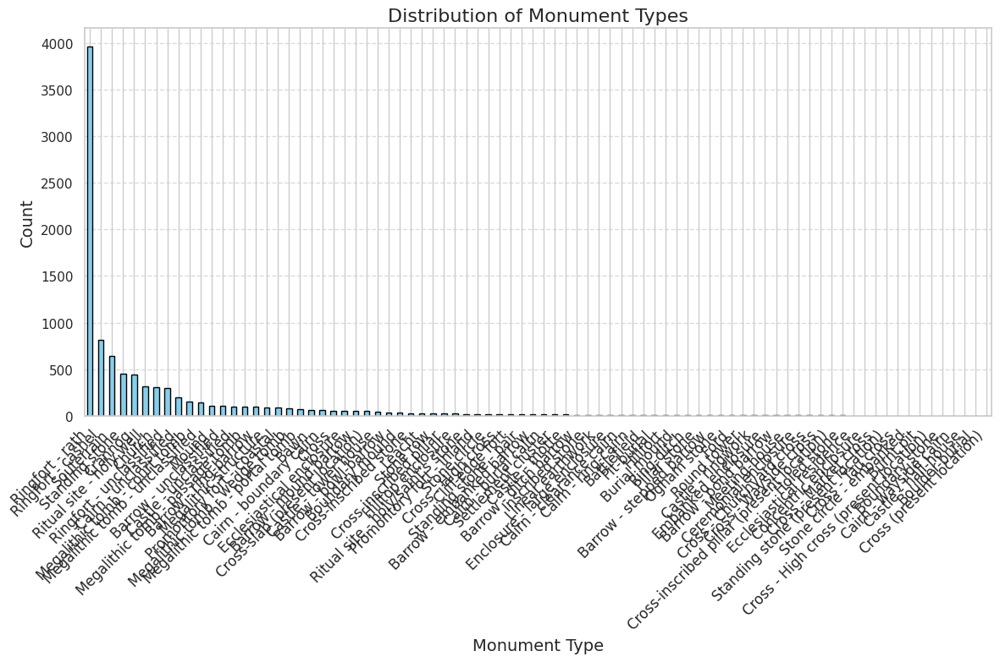

In [11]:
# CREATE BAR CHART OF PROPORTION OF MONUMENT TYPES

# Get the counts of each monument type
monument_counts = sites_nw_clean['MONUMENT_T'].value_counts()

# Create the bar chart
plt.figure(figsize=(12, 8))
monument_counts.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel("Monument Type", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.title("Distribution of Monument Types", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=12)  # Rotate x-axis labels for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Optional: Add gridlines for better readability

plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set consistent plot aesthetics
sns.set(style="whitegrid", palette="muted")

# List of monument classes and their names
monument_classes = [raths, cashels, standing_stones, churches, tower_houses, castles, crannogs, souterrains]
monument_class_names = ['Raths', 'Cashels', 'Standing Stones', 'Churches', 'Tower Houses', 'Castles', 'Crannogs', 'Souterrains']

# Create subplots
fig, axs = plt.subplots(nrows=len(monument_classes), figsize=(10, 10 * len(monument_classes)))

for ax, monument_class, class_name in zip(axs, monument_classes, monument_class_names):
    if monument_class.empty:  # Skip if the class has no data
        ax.set_visible(False)
        continue

    # Extract x and y coordinates directly from the geometry column
    x_coords = monument_class['geometry'].x
    y_coords = monument_class['geometry'].y

    # Plot the basemap
    tuatha_nw_1600_mod.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.5)

    # Create the KDE plot
    sns.kdeplot(x=x_coords, y=y_coords, ax=ax, fill=True, alpha=0.8, cmap="viridis")

    # Set the title with the class name and count
    ax.set_title(f"{class_name} (n={len(monument_class)})", fontsize=14)

    # Add axis labels
    ax.set_xlabel("Longitude", fontsize=12)
    ax.set_ylabel("Latitude", fontsize=12)

    # Set aspect ratio to equal for spatial accuracy
    ax.set_aspect('equal', adjustable='box')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

NameError: name 'raths' is not defined

In [12]:
# Load the rivers , parishes and townlands shapefiles
rivers = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/rivers_nw.shp')
parishes_nw = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/parishes_nw.shp')
townlands_nw = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/townlands_nw.shp')

In [11]:
# Soils data
soils = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/soils_map_nw.shp')
soils.head()

,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,...,ha,URL,UniqueID,DRAINAGE,TEXTURE,DEPTH,SHAPE_Leng,SHAPE_Area,SOC,geometry
0,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.696484,http://gis.teagasc.ie/soils/,2877,Poor,Peat,None,2895.714564,96964.847077,0.0,"POLYGON ((635766.844 809566.516, 635773.42 809..."
1,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,30.859582,http://gis.teagasc.ie/soils/,2887,Poor,Peat,None,8253.807654,308595.830317,0.0,"POLYGON ((634217.362 810308.775, 634285.658 81..."
2,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,None,2737.026809,97054.747857,0.0,"POLYGON ((631261.95 810589.847, 631085.879 810..."
3,29008,TULLYHUNCO,Teallach Dhúnchadha,15,An Cabhán,CAVAN,Ulster,2ae19629-11c1-13a3-e055-000000000001,629128.31,802860.29,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,None,2737.026809,97054.747857,0.0,"POLYGON ((630826.397 810700.688, 631085.879 81..."
4,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,10.334379,http://gis.teagasc.ie/soils/,2931,Poor,Peat,None,2053.385719,103343.786336,0.0,"MULTIPOLYGON (((639154.271 811760.516, 638999...."


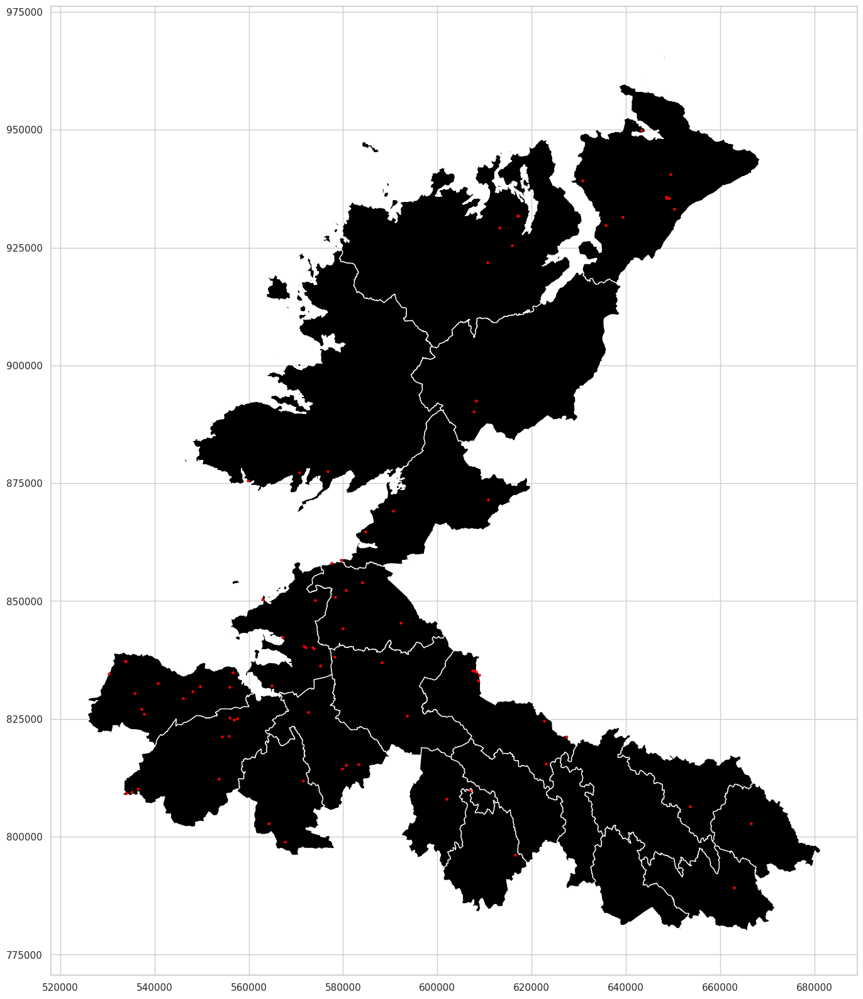

In [15]:
# Plot the wegde tombs
ax = tuatha_nw_1600_mod.plot(color='black', edgecolor='white', figsize=(20, 20))
wedge_tombs.plot(ax=ax, color='red', markersize=5)
plt.show()



In [9]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = wedge_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
wedge_tombs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

NameError: name 'wedge_tombs' is not defined

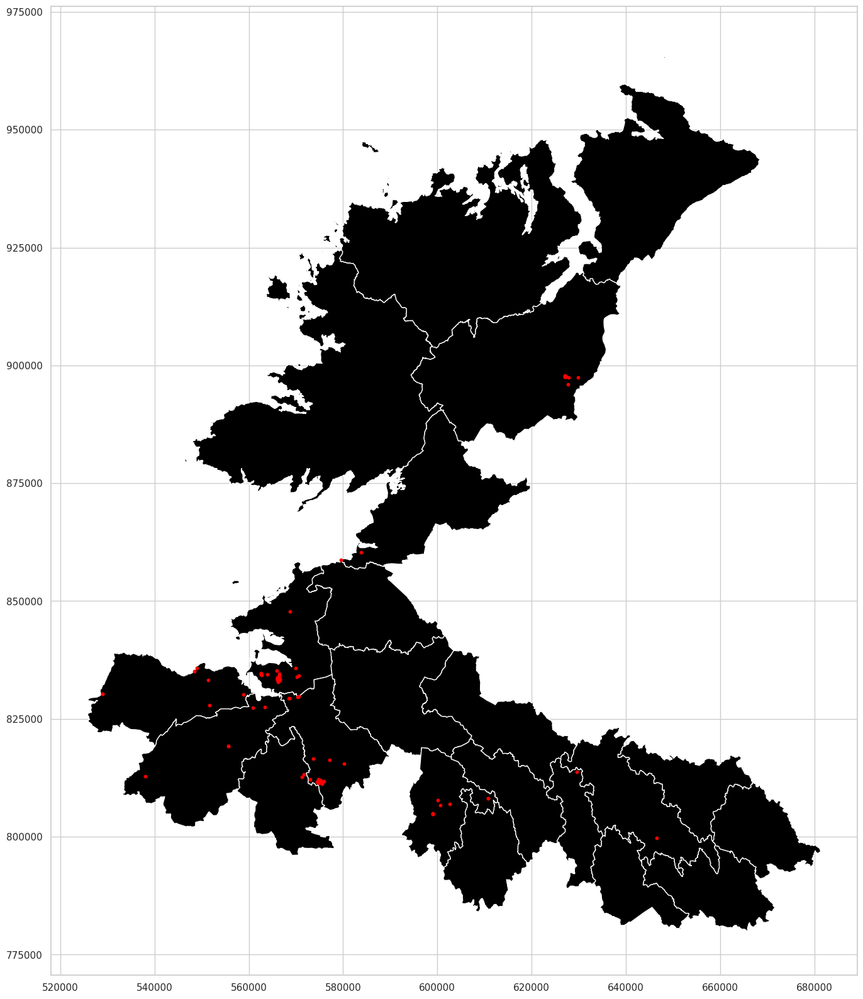

In [16]:
# Plot the Passages Tombs
ax = tuatha_nw_1600_mod.plot(color='black', edgecolor='white', figsize=(20, 20))
#parishes_nw.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)
passage_tombs.plot(ax=ax, color='red', markersize=10)
plt.show()




Number of intersections: 45
Number of objects: 99
Percentage of objects intersecting with a boundary: 45.45%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
363     Situated on the summit of a ridge and with com...
3009    This monument stands within a hillfort (Lacy 1...
3511    This monument is an undifferentiated passage t...
3605    The remains of a cruciform passage tomb surviv...
4696    Situated on a rise in an area of rock outcrop ...
4697    Situated on a local prominence in pasture and ...
6122    Situated at the break of the slope on the S si...
6405    See linked document with details from Seán Ó N...
6410    See linked document (SL020-129----_01.pdf) wit...
6547    Located on a low N-S elevation, on the summit ...
6548    On the summit of Knocknarae Mountain, located ...
6550    This massive circular, limestone cairn (diam. ...
6552    On the summit of Knocknarae Mountain, located ...
6555    On a broad terrace below and to SE of the summ...
6562    Located o

NameError: name 'parishes_nw' is not defined

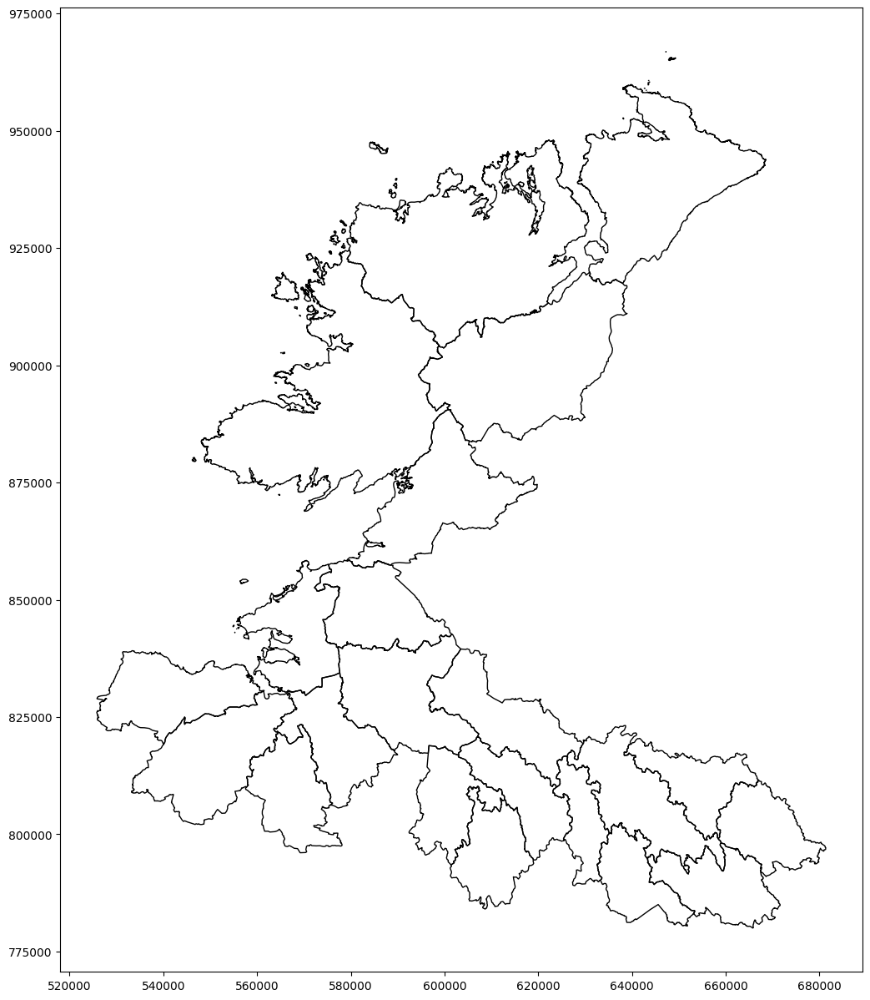

In [26]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = passage_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
passage_tombs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

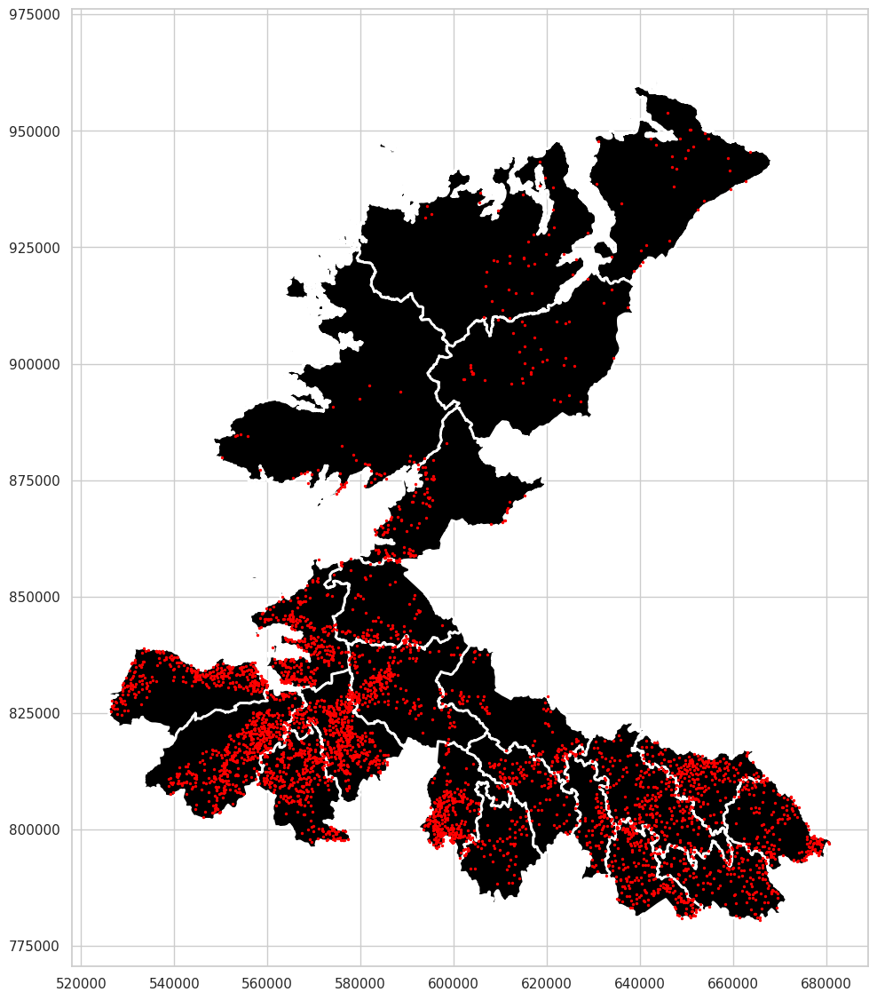

In [19]:
# Plot the RATHS on a map of the North West territories
fig, ax = plt.subplots(figsize=(14,14))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=2)
#townlands_nw.plot(ax=ax, color='black', edgecolor='white', alpha=0.5, linewidth=0.5)
#rivers.plot(ax=ax, color='blue')    
raths.plot(ax=ax, color='red', markersize=2)
plt.show()


Number of intersections: 2134
Number of objects: 3961
Percentage of objects intersecting with a boundary: 53.88%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
5       Raised circular area (int. diam 37.5m) enclose...
6       Probably originally a rath later transformed i...
7       Probably originally a rath later transformed i...
8       Raised oval area (int. dims. 48.8m N-S; 32.7m ...
9       An earlier report (OPW 1970) described a raise...
                              ...                        
9430    In lowlying pasture, at the narrow S corner of...
9433    In pasture, crowning the summit of a steep-sid...
9450    Situated in a col with slightly higher ground ...
9456    Located at the bottom of a gentle E-facing slo...
9481    In good coastal grassland, 1km S of Ballysadar...
Name: WEB_NOTES, Length: 2134, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([   5,    6,    7,    8,    9,   11,   13,   21,   22,   27,
       ..

NameError: name 'parishes_nw' is not defined

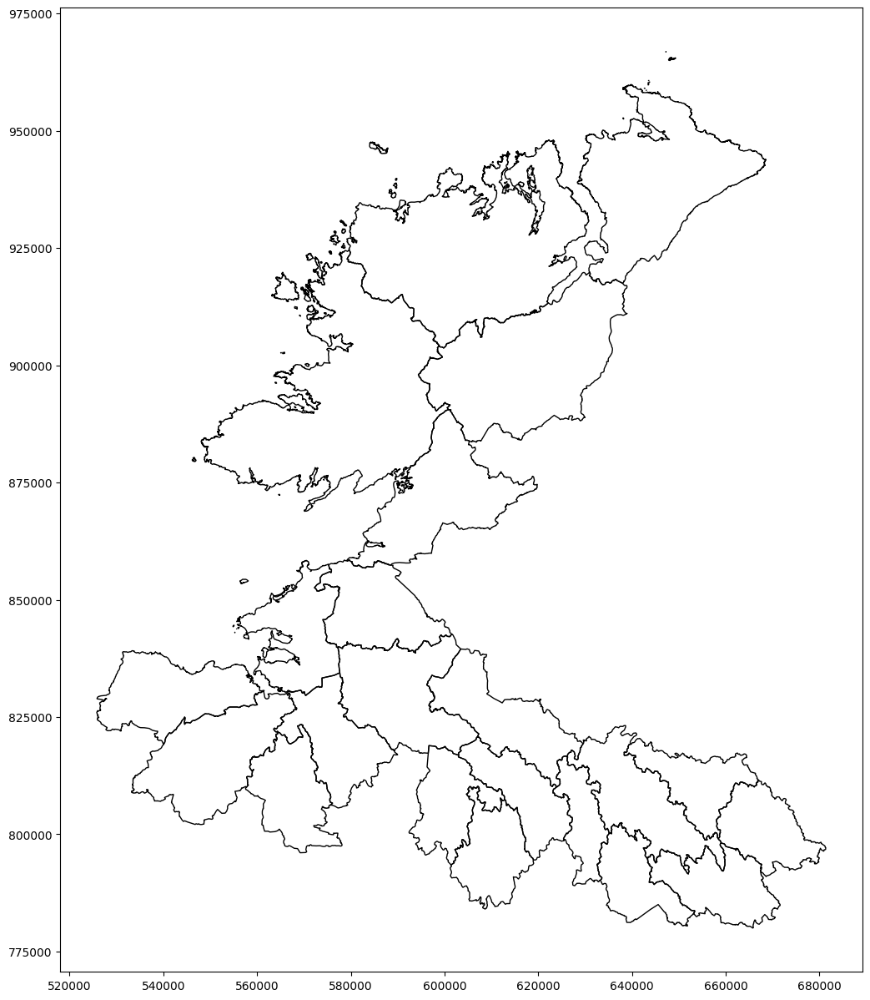

In [27]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = raths # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
raths.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

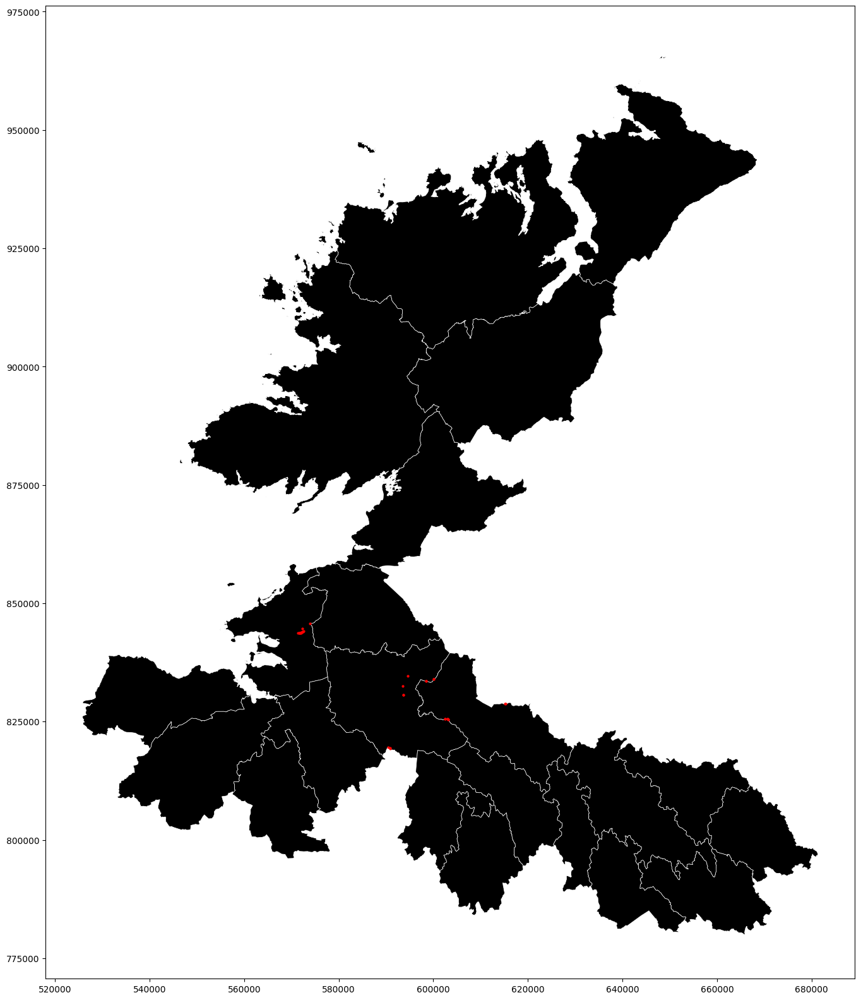

In [ ]:
# Plot the Boundary mounds on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax,color="black", edgecolor='white', linewidth=0.5)
boundary_mounds.plot(ax=ax, color='red', markersize=4)
plt.show()


Number of intersections: 17
Number of objects: 33
Percentage of objects intersecting with a boundary: 51.52%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
152     Not marked on OS 1836 or 1876 eds. Situated on...
178     Not marked on OS 1836 or 1876 eds. Situated on...
182     Not marked on OS 1836 or 1876 eds. Situated on...
216     In rough mountainous terrain. One of a series ...
217     In rough mountainous terrain. One of a series ...
1883    About 40 mounds in a SW-NE line are marked onl...
1884    About 80 mounds in a WNW-ESE line are marked o...
4263    About 80 mounds in a WNW-ESE line are marked o...
4545    Marked only on the 1907 edition of the OS 6-in...
4546    Marked only on the 1907 edition of the OS 6-in...
5132    Marked only on the 1914 edition of the Roscomm...
5133    Situated on a broad E-W ridge. It is marked on...
5227    About 40 mounds in a SW-NE line are marked onl...
5233    Situated on a broad E-W ridge. It is marked on...
5885    Listed in

NameError: name 'parishes_nw' is not defined

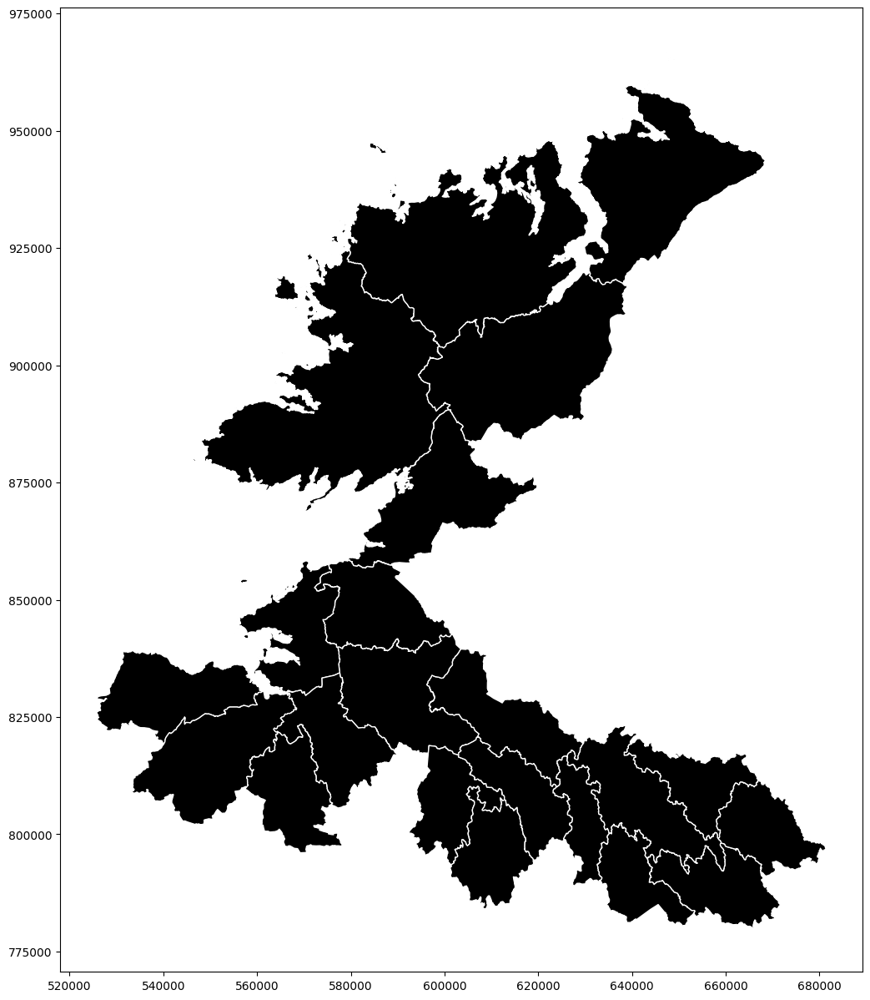

In [28]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = boundary_mounds # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.plot(ax=ax, color='black', edgecolor="white", linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
boundary_mounds.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

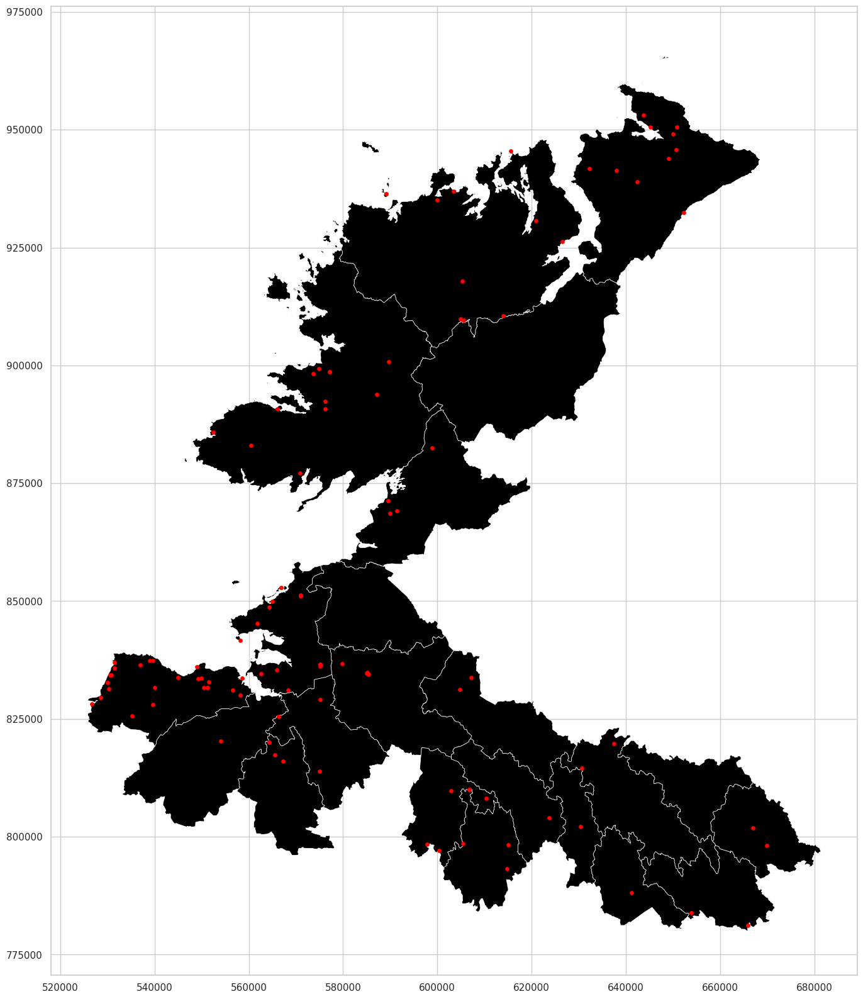

In [20]:
# Plot the mounds on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax,color="black", edgecolor='white', linewidth=0.5)
mounds.plot(ax=ax, color='red', markersize=15)
plt.show()


Number of intersections: 63
Number of objects: 111
Percentage of objects intersecting with a boundary: 56.76%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
1721    The Archaeological Survey of Ireland (ASI) is ...
1788    A roughly circular round-topped, grass-covered...
1797    The Archaeological Survey of Ireland (ASI) is ...
1802    The Archaeological Survey of Ireland (ASI) is ...
1874    The Archaeological Survey of Ireland (ASI) is ...
                              ...                        
9268    In pasture, on the top of a broad low hill. Gr...
9269    In pasture, located on top of a steep slope wh...
9305    The Archaeological Survey of Ireland (ASI) is ...
9375    In pasture, located at Raghly Point on the SE ...
9472    Reported (5-10-2021) by Mr Aidan Harte, Projec...
Name: WEB_NOTES, Length: 63, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([1721, 1788, 1797, 1802, 1874, 1912, 1923, 1994, 2175, 2331, 2374, 2461,
  

NameError: name 'parishes_nw' is not defined

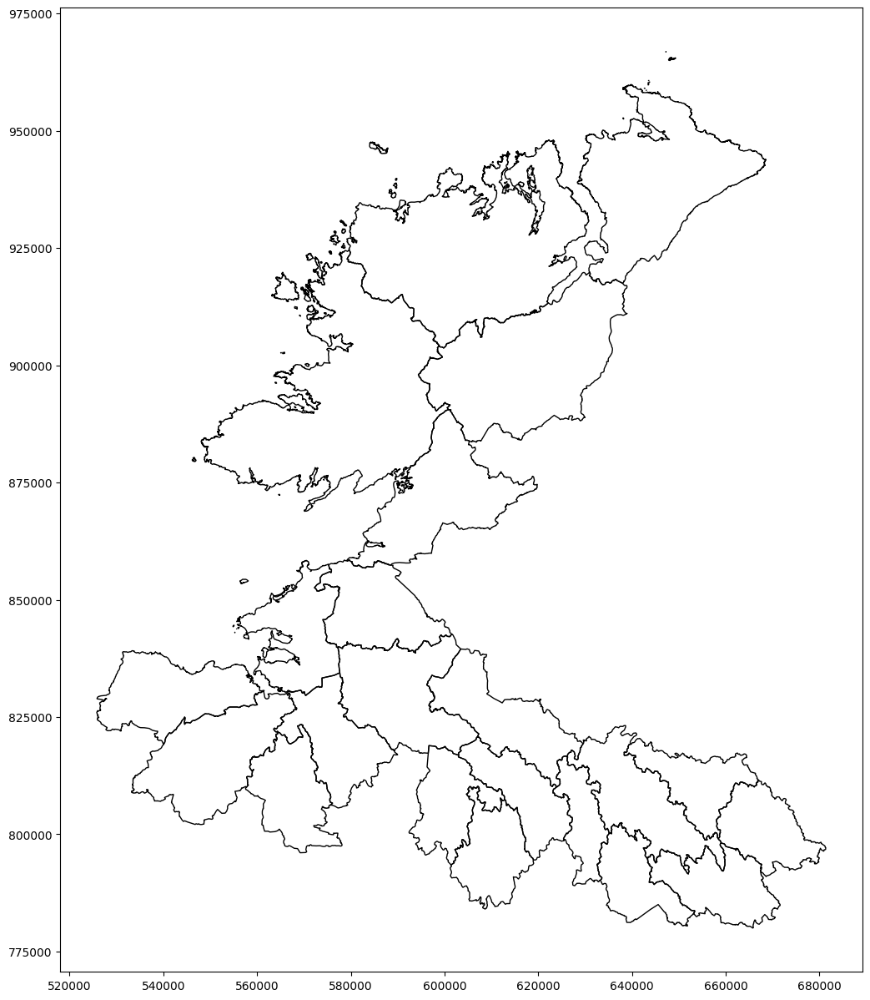

In [29]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = mounds # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
mounds.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

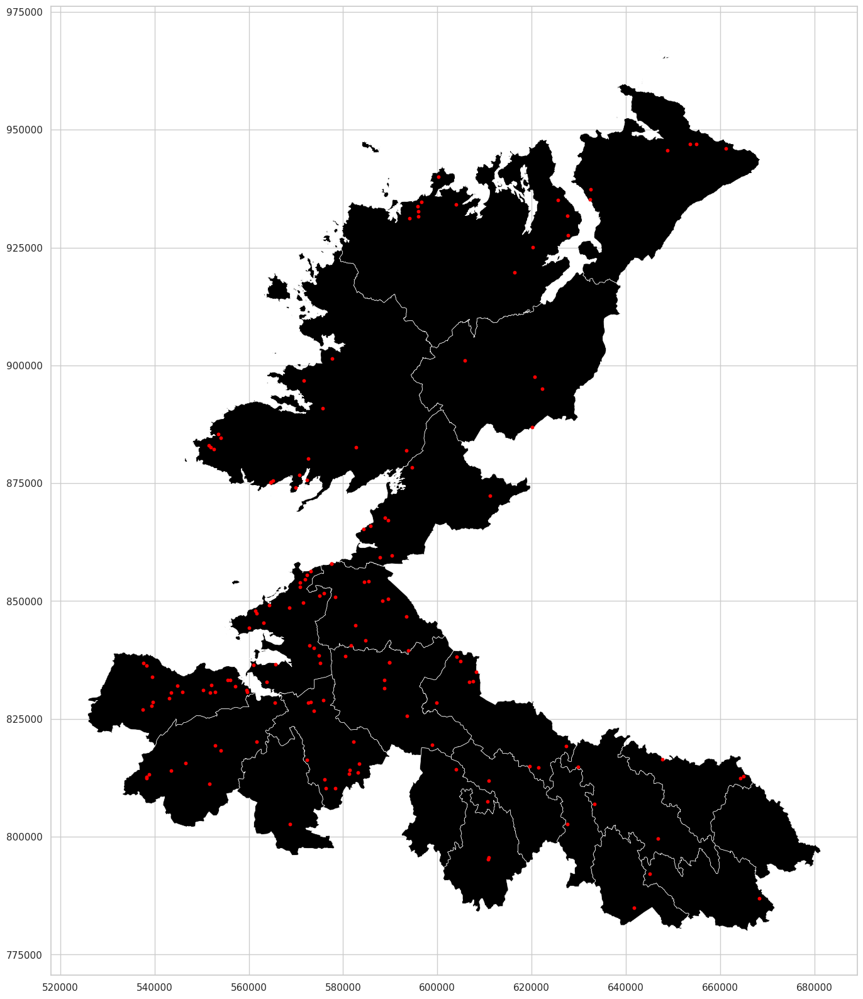

In [21]:
# Plot the court tombs on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)   
#rivers.plot(ax=ax, color='blue', markersize=1) 
court_tombs.plot(ax=ax, color='red', markersize=10)
plt.show()

plt.show()

In [22]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = court_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
court_tombs.plot(ax=ax, color='black', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

NameError: name 'buffer_object_intersection' is not defined

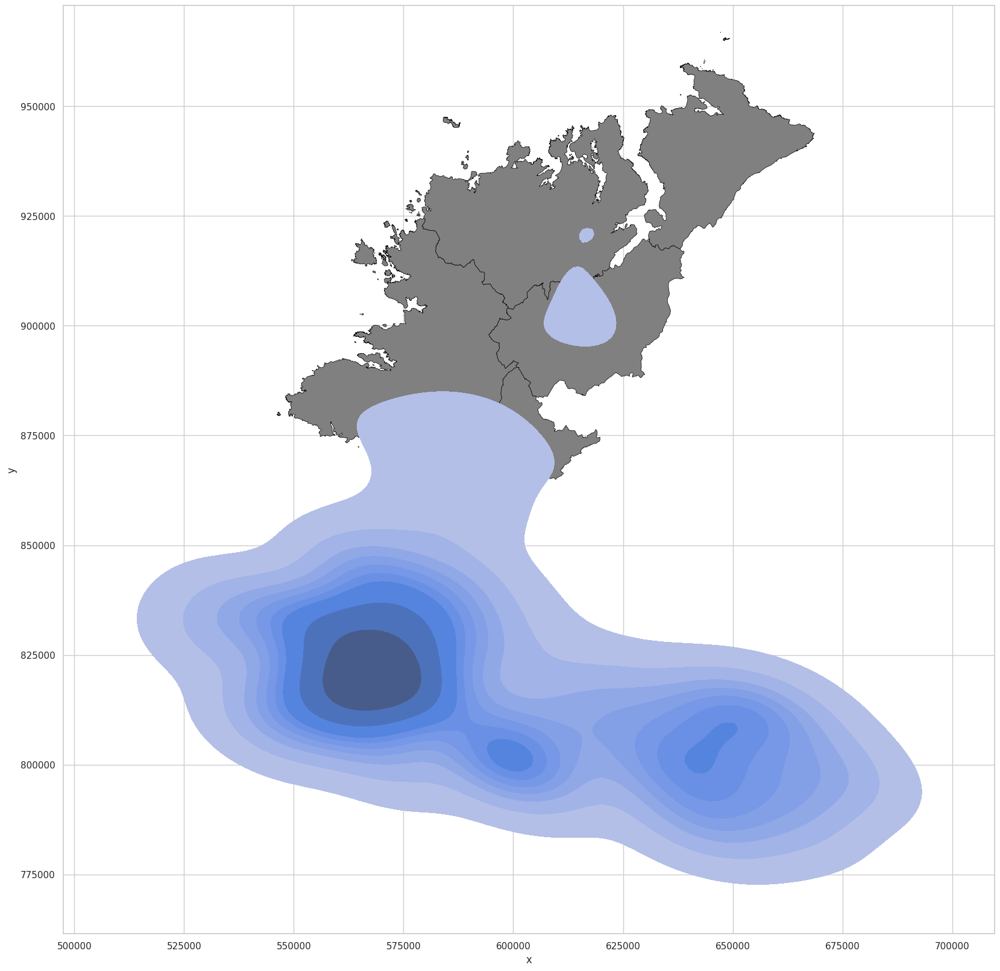

In [23]:
# Create a KDE plot

# Create a new DataFrame with the x and y coordinates of the raths
raths_coords = pd.DataFrame({'x': raths['geometry'].x, 'y': raths['geometry'].y})

# Plot the basemap
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='black', linewidth=0.5)

# Create the KDE plot
sns.kdeplot(data=raths_coords, x='x', y='y', ax=ax, fill=True)

plt.show()



 


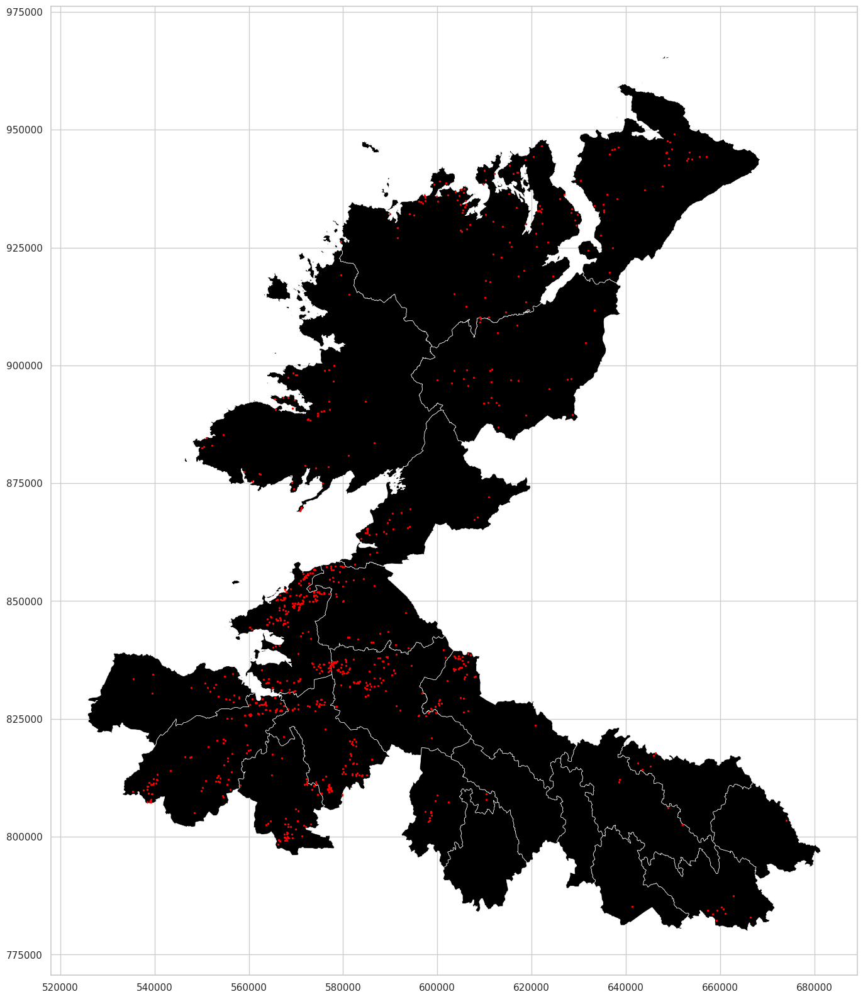

In [24]:
# Plot the CASHELS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20),)
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
cashels.plot(ax=ax, color='red', markersize=2, )
plt.show()

In [25]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = cashels # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)

# Plot the data points
cashels.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

NameError: name 'buffer_object_intersection' is not defined

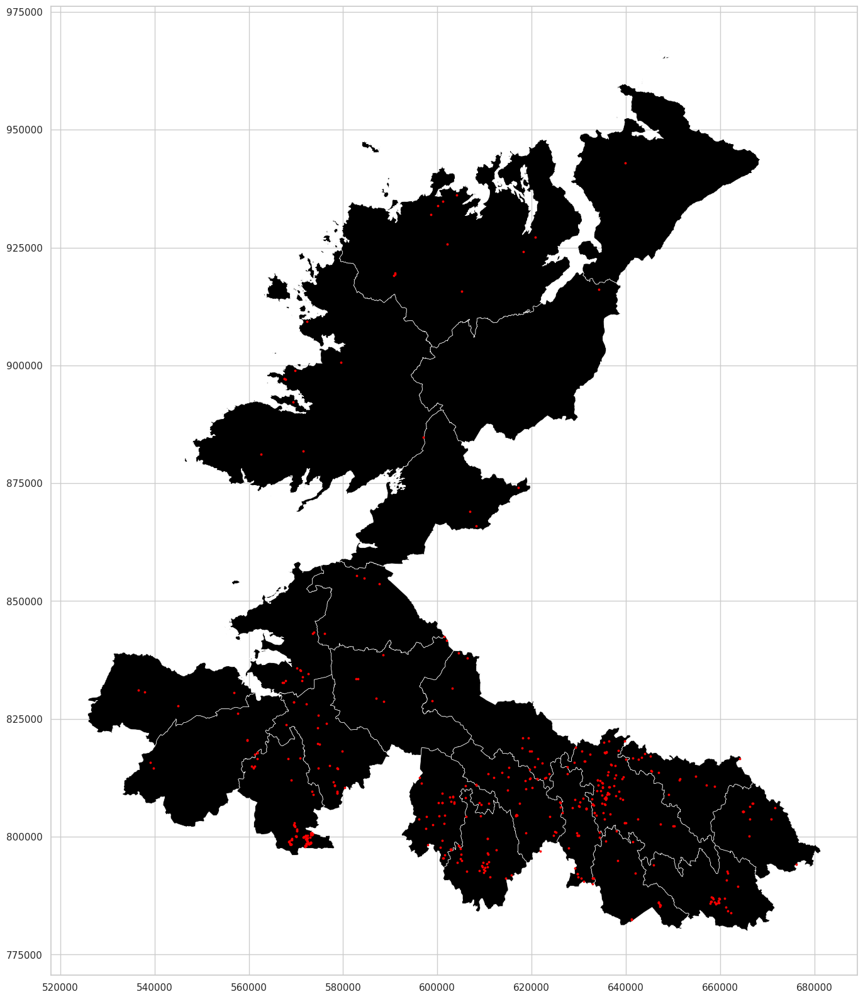

In [26]:
# Plot the CRANNOGS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
crannogs.plot(ax=ax, color='red', markersize=3)
plt.show()

Number of intersections: 254
Number of objects: 447
Percentage of objects intersecting with a boundary: 56.82%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
26      Subcircular island (diam. c. 20m) in Lough Gow...
97      An almost circular tree-and-grass-covered isla...
109     The Archaeological Survey of Ireland (ASI) is ...
110     The Archaeological Survey of Ireland (ASI) is ...
111     The Archaeological Survey of Ireland (ASI) is ...
                              ...                        
9471    Situated just off the S shore of Mill Lough, a...
9473    Located c. 40m from the SE shore of the rectan...
9474    Located towards the W end of the teardrop-shap...
9476    A small island (diam. c. 10m) is depicted only...
9477    Located in a small U-shaped bay (dims c. 90m E...
Name: WEB_NOTES, Length: 254, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  26,   97,  109,  110,  111,  136,  250,  267,  274,  275,
       ...
 

NameError: name 'parishes_nw' is not defined

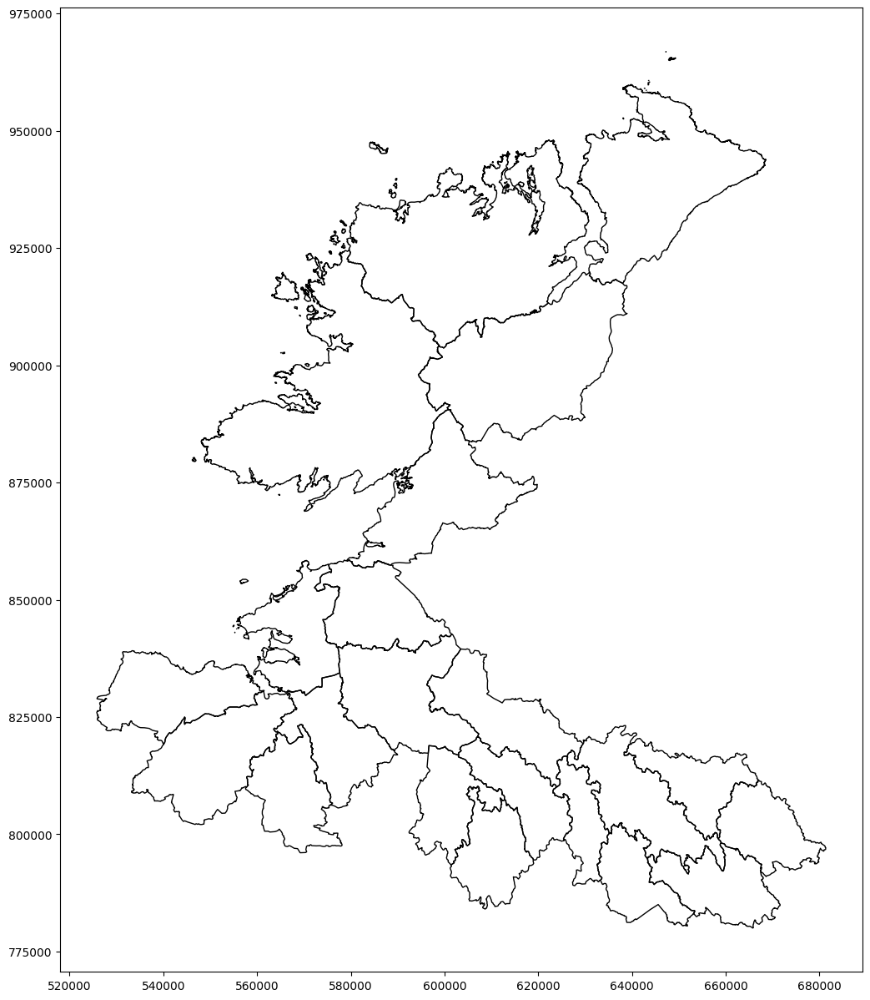

In [32]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = crannogs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
crannogs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

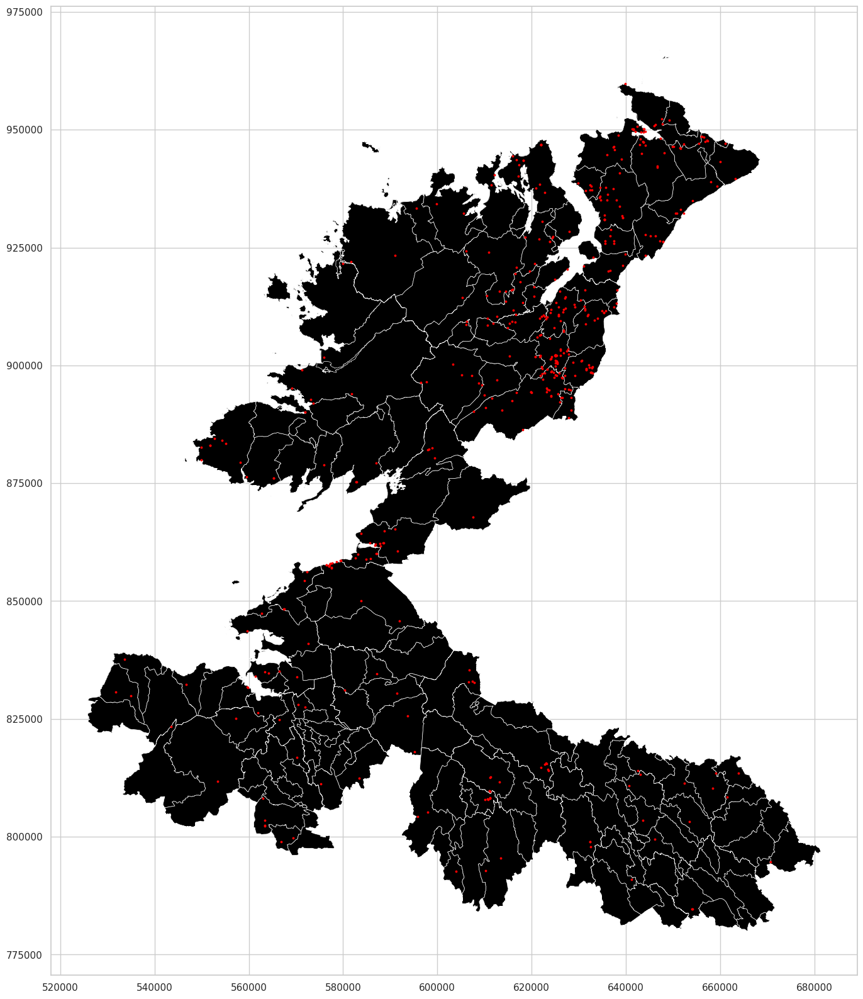

In [27]:
# Plot the standing stones on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)  
parishes_nw.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5) 
standing_stones.plot(ax=ax, color='red', markersize=3)
plt.show()

CHURCHES

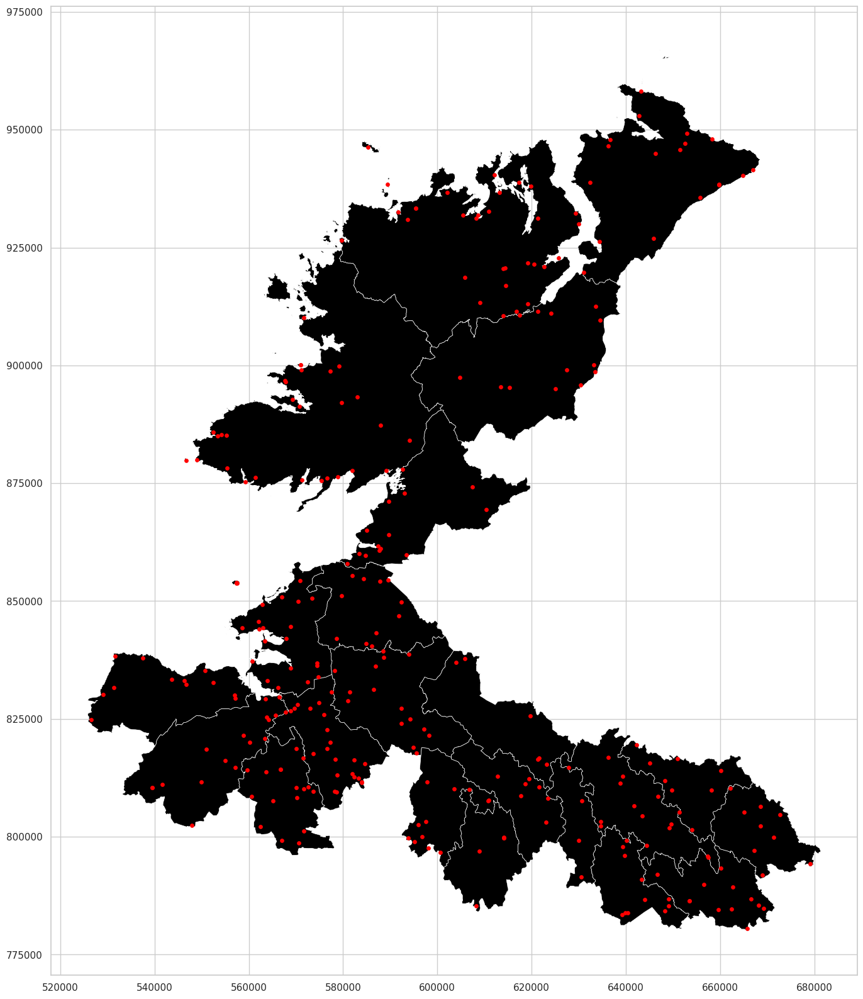

In [29]:
# Plot the churches on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)   
#parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)
churches.plot(ax=ax, color='red', markersize=15)
plt.show()



Number of intersections: 204
Number of objects: 311
Percentage of objects intersecting with a boundary: 65.59%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
10      Davies (1948, 110) speculated that this childr...
23      Davies (1948, 109) suggested that this was an ...
24      Marked 'Fort', with a 'Church' indicated withi...
108     Described in the Inventory of Irish Architectu...
131     Rectangular church (int. dims. 20.8m E-W; 5.8m...
                              ...                        
9047    In a small grove of trees on top of a low rise...
9086    The Archaeological Survey of Ireland (ASI) is ...
9233    A well (DG027-019----) which is depicted on th...
9238    A small rectangular disused graveyard (DG079-0...
9260    Situated in Ballynacarrow village, on the NW s...
Name: WEB_NOTES, Length: 204, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  10,   23,   24,  108,  131,  225,  330,  401,  533,  556,
       ...
 

NameError: name 'parishes_nw' is not defined

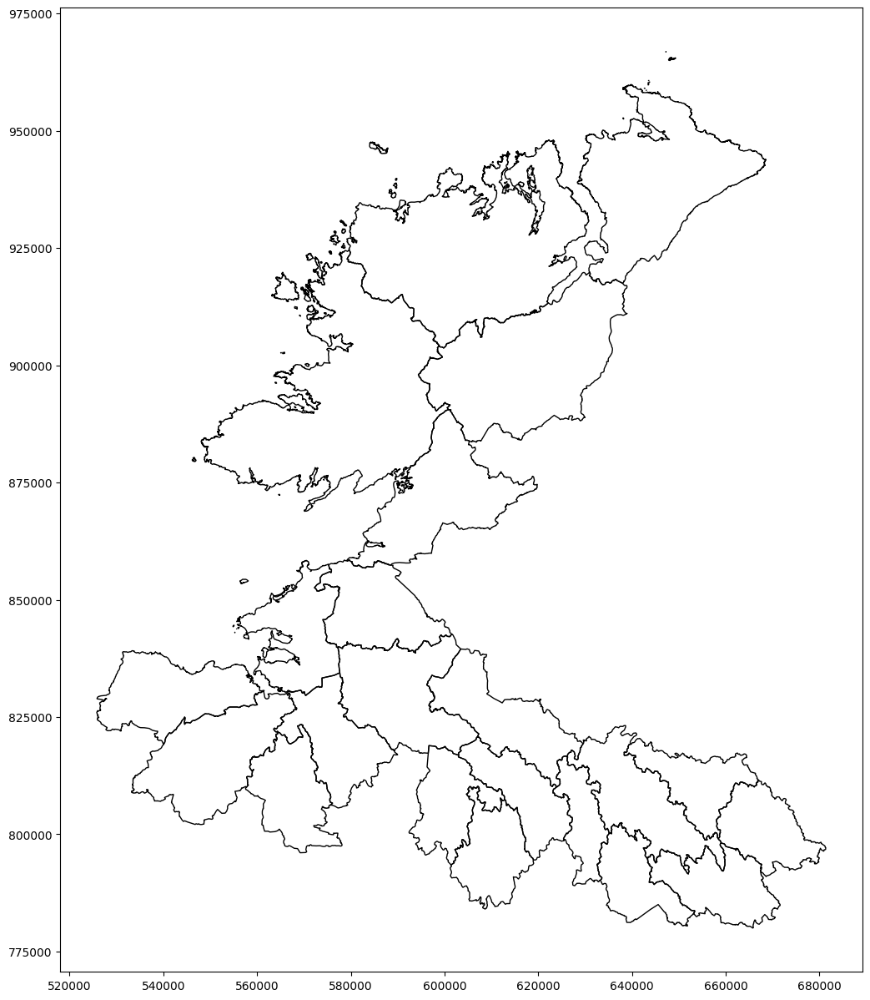

In [33]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = churches # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
churches.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

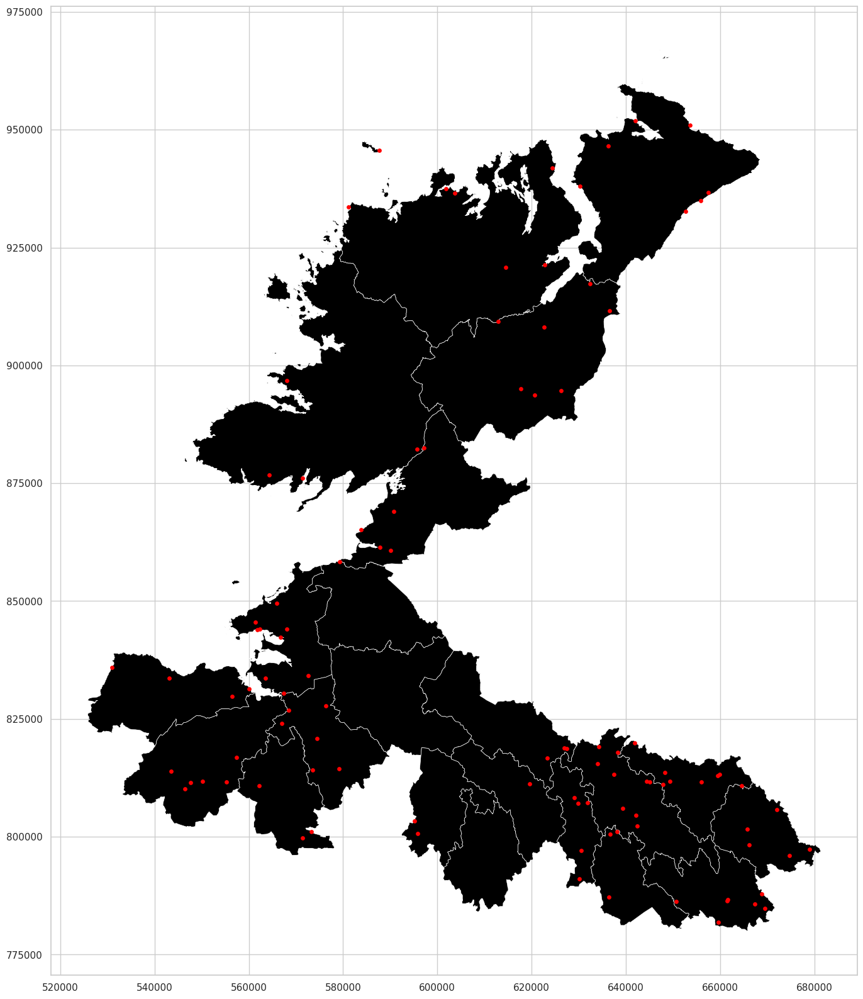

In [30]:
# Plot the castles on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
castles.plot(ax=ax, color='red', markersize=15)
plt.show()

Number of intersections: 69
Number of objects: 102
Percentage of objects intersecting with a boundary: 67.65%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
14      Davies (1948a, 115) recorded the site of a pla...
93      Reputed to be the site of a 16th-century O'Rei...
248     Captain Culme and Walter Talbot were granted 1...
257     Built by Sir Hugh Wirrall in 1618, subsequentl...
259     Henry (1987, 23) writing in 1739 recorded a re...
                              ...                        
7441    In a meadow, on top of a rise. There are now n...
8035    In rough pasture, on slightly raised level gro...
8062    In low-lying level terrain. There are no visib...
8920    In the SE quadrant of a moated site (SL045-007...
8984    In rough pasture, at Castle Point which is the...
Name: WEB_NOTES, Length: 69, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  14,   93,  248,  257,  259,  270,  281,  338,  468,  512,  513,  549,
  

NameError: name 'parishes_nw' is not defined

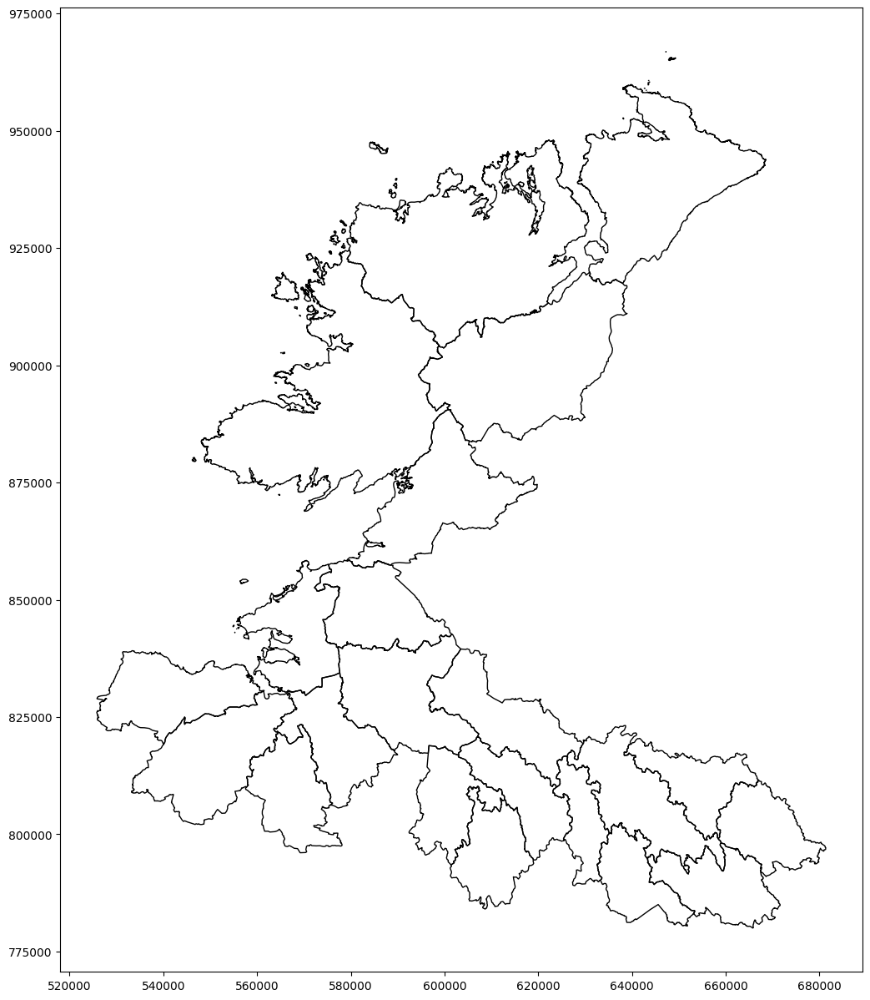

In [34]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = castles # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
castles.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

TOWER HOUSES


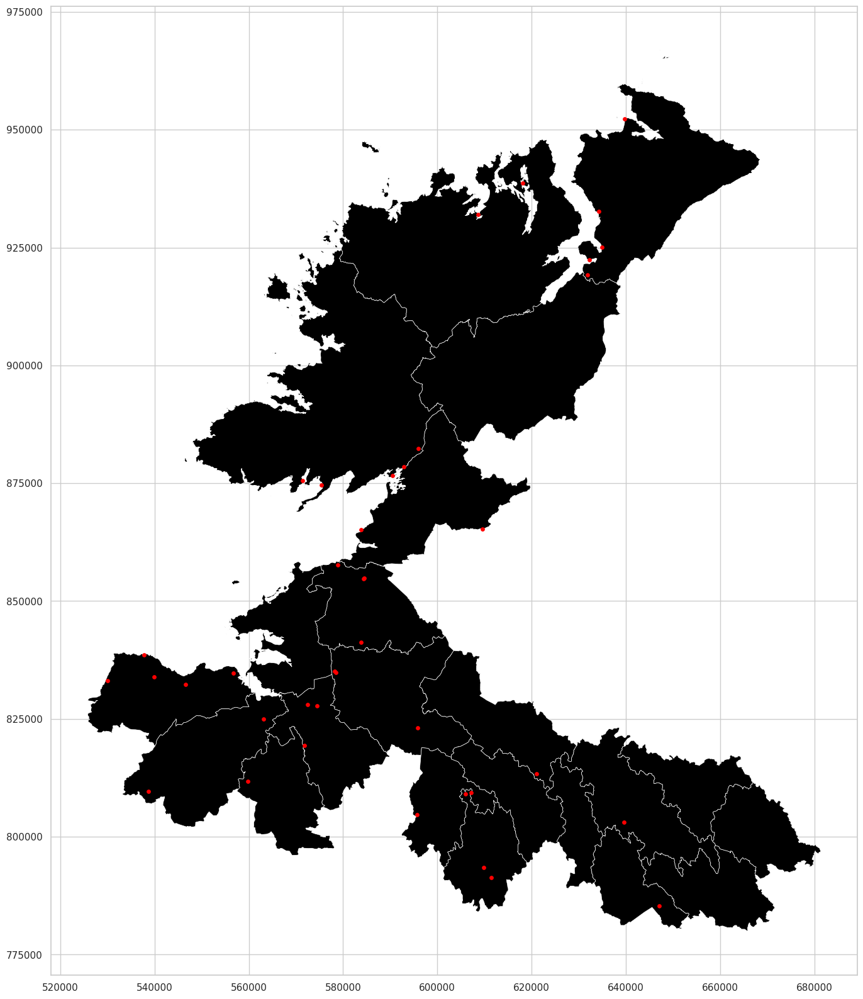

In [31]:
# Plot the tower houses  on a map of the North West territories
# Label each tower house with its name
# Add a legend
# Add a title

fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5, )    
tower_houses.plot(ax=ax, color='red', markersize=15, label='Tower Houses')
plt.show()

In [28]:
territory_boundary_union = territory_boundary.boundary.unary_union
num_intersections, monument_buffer, intersecting_objects = buffer_object_intersection(
    archae_objects=tower_houses,
    buffer_distance=2000,
    boundary_union=territory_boundary_union
)

/tmp/ipykernel_131320/2796200370.py:1: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  territory_boundary_union = territory_boundary.boundary.unary_union


TypeError: buffer_object_intersection() got an unexpected keyword argument 'boundary_union'

BOUNDARY CAIRNS

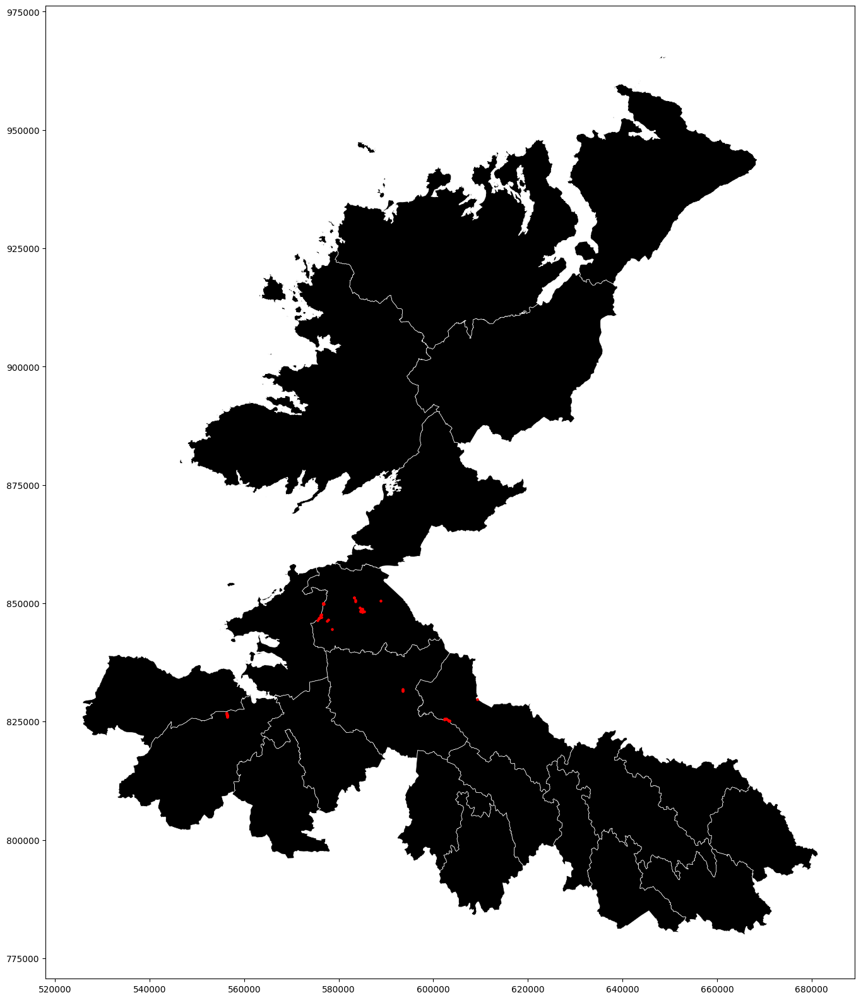

In [ ]:
# Plot the BOUNDARY CAIRNS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
boundary_cairns.plot(ax=ax, color='red', markersize=5)
plt.show()

Number of intersections: 43
Number of objects: 62
Percentage of objects intersecting with a boundary: 69.35%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
153     Not marked on OS 1836 or 1876 eds. Situated on...
155     Not marked on OS 1836 or 1876 eds. Situated on...
158     Not marked on OS 1836 or 1876 eds. Situated on...
183     Not marked on OS 1836 or 1876 eds. Situated on...
185     Not marked on OS 1836 or 1876 eds. Situated on...
191     Not marked on OS 1836 or 1876 eds. Situated on...
3950    Towards the top of a NE-facing slope which is ...
3951    At the summit of a ridge running N from Truskm...
3959    Marked only on the 1909 ed. of the OS 6-inch m...
3960    Marked only on the 1909 ed. of the OS 6-inch m...
3961    Marked only on the 1909 ed. of the OS 6-inch m...
3962    Marked only on the 1909 ed. of the OS 6-inch m...
3964    Marked only on the 1909 ed. of the OS 6-inch m...
3965    Marked only on the 1909 ed. of the OS 6-inch m...
3966    Marked on

NameError: name 'parishes_nw' is not defined

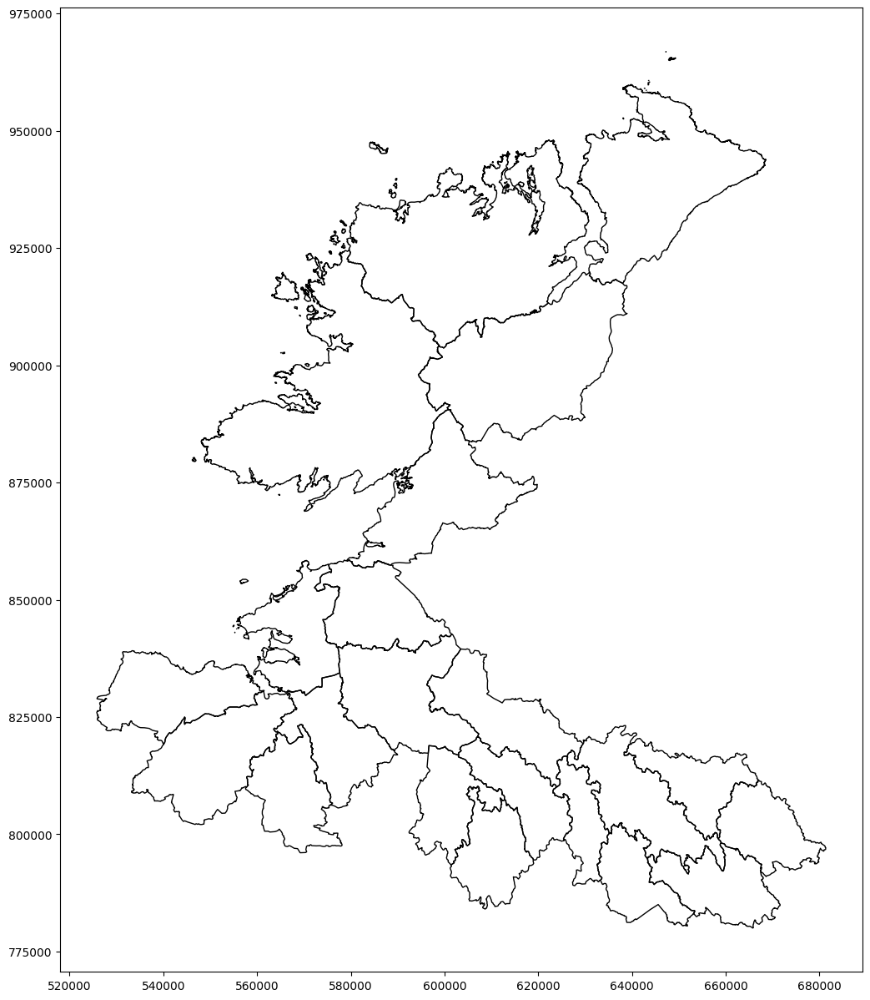

In [36]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = boundary_cairns # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
tuatha_nw_1600_mod.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
boundary_cairns.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

CAIRNS 

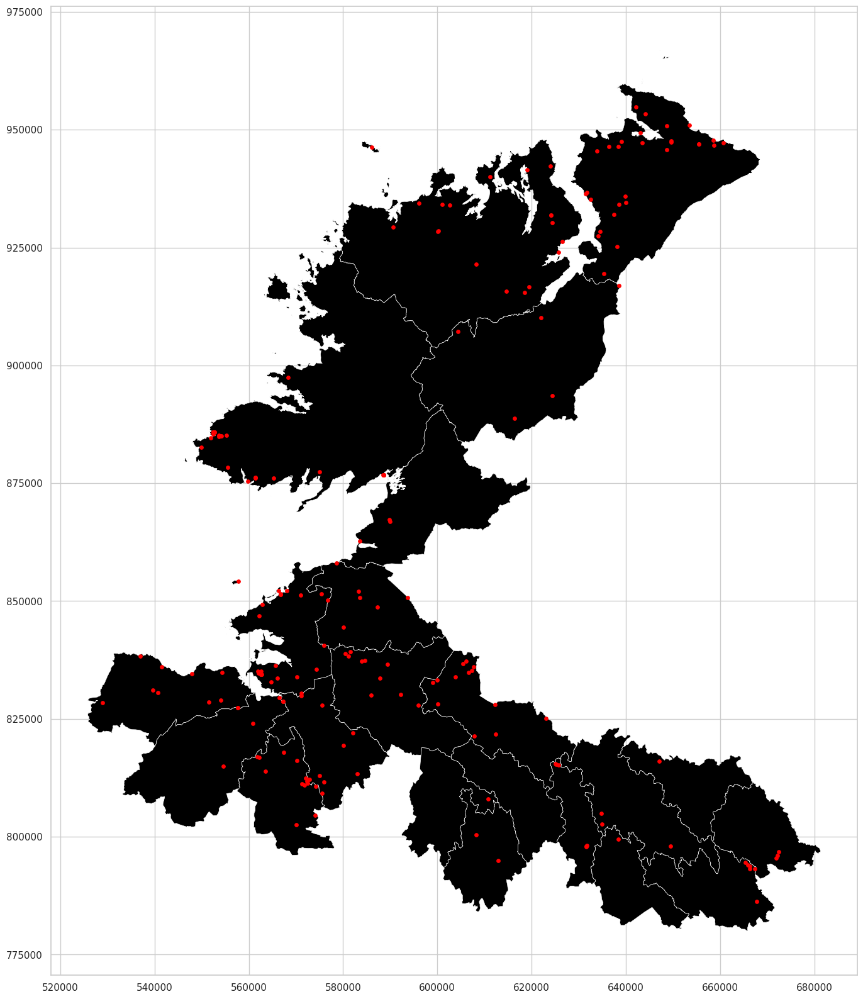

In [32]:
# Plot the CAIRNS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
cairns.plot(ax=ax, color='red', markersize=15)
plt.show()

BATTLEFIELDS

In [33]:
# Filter the dataframe for the 'Battlefield' category
battlefields = sites_nw_features[sites_nw_features['MONUMENT_T'] == 'Battlefield']

fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white', linewidth=2, alpha=0.8)

# Plot the 'Battlefield' category
battlefields.plot(ax=ax, color='black', markersize=20, label='Battlefield')

plt.show()

# 71% of the battlefields intersect with a boundary

NameError: name 'sites_nw_features' is not defined

In [20]:
buffer_distance = 2000 # Adjust the buffer size as needed
archae_objects = battlefields # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod 

num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
#parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
battlefields.plot(ax=ax, color='black', markersize=20)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

NameError: name 'battlefields' is not defined

In [ ]:
# get the WEB_NOTES entries for these Battlefields
battlefields['WEB_NOTES']



9274    The Archaeological Survey of Ireland (ASI) is ...
9275    The Archaeological Survey of Ireland (ASI) is ...
9276    The Archaeological Survey of Ireland (ASI) is ...
9277    The Archaeological Survey of Ireland (ASI) is ...
9278    The Archaeological Survey of Ireland (ASI) is ...
9279    The Archaeological Survey of Ireland (ASI) is ...
9280    The Archaeological Survey of Ireland (ASI) is ...
Name: WEB_NOTES, dtype: object

In [26]:
buffer_distance = 2000 # Adjust the buffer size as needed
archae_objects = cairns # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod 

num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
tuatha_nw_1600_mod.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
cairns.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

Number of intersections: 0
Number of objects: 202
Percentage of objects intersecting with a boundary: 0.00%
WEB_NOTE for objects intersecting with the boundary:
Series([], Name: WEB_NOTES, dtype: object)


/tmp/ipykernel_131320/3394032232.py:29: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  intersections = monument_buffer.intersects(boundary_union)
/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/geopandas/geodataframe.py:1750: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


ValueError: too many values to unpack (expected 2)

 THE SPATIAL DISTRIBUTION OF MONUMENTS RELATIVE TO BOUNDARIES.
 

In [25]:
def buffer_object_intersection(
    archae_objects: gpd.GeoDataFrame,
    buffer_distance: float,
    boundary_union: gpd.GeoSeries
) -> tuple[int, gpd.GeoSeries, gpd.GeoDataFrame]:
    """
    Determines whether archaeological objects are within a certain distance of a boundary.

    Parameters:
        archae_objects (gpd.GeoDataFrame): GeoDataFrame containing archaeological objects.
        buffer_distance (float): Distance (in the same units as the GeoDataFrame) for the buffer.
        boundary_union (gpd.GeoSeries): Unified boundary geometry.

    Returns:
        tuple[int, gpd.GeoSeries, gpd.GeoDataFrame]: Number of intersections, buffer geometries, and intersecting objects.
    """
    if archae_objects.empty:
        print("No archaeological objects provided.")
        return 0, None, None

    if archae_objects.is_empty.any():
        print("Some geometries are empty. These will be ignored.")
        archae_objects = archae_objects[~archae_objects.is_empty]

    # Create a buffer around each archaeological object
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)

    # Check for intersections with the boundary
    intersections = monument_buffer.intersects(boundary_union)

    # Count the number of intersections
    num_intersections = intersections.sum()

    # Filter intersecting objects
    intersecting_objects = archae_objects[intersections]

    # Print summary
    print(f"Number of intersections: {num_intersections}")
    print(f"Number of objects: {len(archae_objects)}")
    print(f"Percentage of objects intersecting with a boundary: {num_intersections / len(archae_objects) * 100:.2f}%")
    print("WEB_NOTE for objects intersecting with the boundary:")
    print(intersecting_objects['WEB_NOTES'])

    return num_intersections, monument_buffer, intersecting_objects



FURTHER INVESTIGATION/FEATURE Creation FROM DATA

In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point
from scipy import stats
import tqdm

def calculate_intersection_percentage(archae_objects, buffer_distance, boundary):
    """Same as before"""
    if archae_objects.empty:
        return 0
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)
    intersections = monument_buffer.intersects(boundary)
    return (intersections.sum() / len(archae_objects)) * 100

def monte_carlo_test(points, study_area, buffer_distance, boundary, n_simulations=99):
    """
    Perform Monte Carlo simulation to test for significance of spatial patterns.
    
    Parameters:
        points (GeoDataFrame): Original points to analyze
        study_area (GeoDataFrame): Area containing the points
        buffer_distance (float): Buffer distance for intersection analysis
        boundary (GeoSeries): Boundary to test against
        n_simulations (int): Number of Monte Carlo simulations
    
    Returns:
        tuple: (observed percentage, p-value, z-score)
    """
    observed = calculate_intersection_percentage(points, buffer_distance, boundary)
    simulated = []
    
    # Get study area bounds
    minx, miny, maxx, maxy = study_area.total_bounds
    
    # Run simulations
    for _ in range(n_simulations):
        # Generate random points
        random_points = [Point(np.random.uniform(minx, maxx), 
                             np.random.uniform(miny, maxy)) 
                        for _ in range(len(points))]
        
        # Create GeoDataFrame from random points
        random_gdf = gpd.GeoDataFrame(geometry=random_points, crs=points.crs)
        
        # Calculate percentage for random points
        random_percentage = calculate_intersection_percentage(random_gdf, buffer_distance, boundary)
        simulated.append(random_percentage)
    
    # Calculate statistics
    simulated = np.array(simulated)
    z_score = (observed - np.mean(simulated)) / np.std(simulated)
    p_value = np.sum(np.abs(simulated - np.mean(simulated)) >= 
                     np.abs(observed - np.mean(simulated))) / n_simulations
    
    return observed, p_value, z_score

# Main analysis
buffer_distance = 1500
results = []

# Create unified boundary
boundary_union = tuatha_nw_1600_mod.boundary.unary_union

# Ensure CRS consistency
if sites_nw_clean.crs != tuatha_nw_1600_mod.crs:
    sites_nw_clean = sites_nw_clean.to_crs(tuatha_nw_1600_mod.crs)

# Analyze each monument type
for monument_type in tqdm(sites_nw_clean['MONUMENT_T'].unique(), desc="Analyzing monuments"):
    monuments = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == monument_type]
    count = len(monuments)
    
    if count >= 5:  # Only analyze types with at least 5 examples
        observed, p_value, z_score = monte_carlo_test(
            monuments, 
            tuatha_nw_1600_mod, 
            buffer_distance, 
            boundary_union
        )
        
        results.append({
            'MONUMENT_T': monument_type,
            'Count': count,
            'Observed_Percentage': observed,
            'P_Value': p_value,
            'Z_Score': z_score,
            'Pattern': 'Clustered' if (z_score > 1.96 and p_value < 0.05) else
                      'Dispersed' if (z_score < -1.96 and p_value < 0.05) else
                      'Random'
        })

# Create results DataFrame
results_df = pd.DataFrame(results)

# Sort by absolute Z-score to show strongest patterns first
results_df = results_df.sort_values('Z_Score', key=abs, ascending=False)

# Save results
results_df.to_csv('monument_spatial_patterns.csv', index=False)

# Display significant patterns
significant_patterns = results_df[results_df['P_Value'] < 0.05]
print("\nSignificant Spatial Patterns (p < 0.05):")
print(significant_patterns[['MONUMENT_T', 'Count', 'Observed_Percentage', 
                          'Z_Score', 'Pattern']])

/tmp/ipykernel_154560/449735008.py:62: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary_union = tuatha_nw_1600_mod.boundary.unary_union



Significant Spatial Patterns (p < 0.05):
                          MONUMENT_T  Count  Observed_Percentage    Z_Score  \
2                    Ringfort - rath   3961            42.034840  26.714592   
38         Promontory fort - coastal     87           100.000000  20.213327   
3                             Church    311            57.877814  17.134751   
11           Ritual site - holy well    314            55.732484  15.538651   
4               Cairn - unclassified    202            61.881188  13.253138   
47     Cross-slab (present location)     49            95.918367  13.181798   
12                 Ringfort - cashel    811            41.923551  13.163720   
9                         Souterrain    641            43.057722  13.050943   
6                     Standing stone    448            42.857143  11.687008   
46                            Leacht     28            96.428571  10.590834   
15             Barrow - unclassified    108            58.333333  10.468214   
8         

/tmp/ipykernel_154560/2460844641.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Z_Score', y='MONUMENT_T', data=df_sorted, ax=ax1,


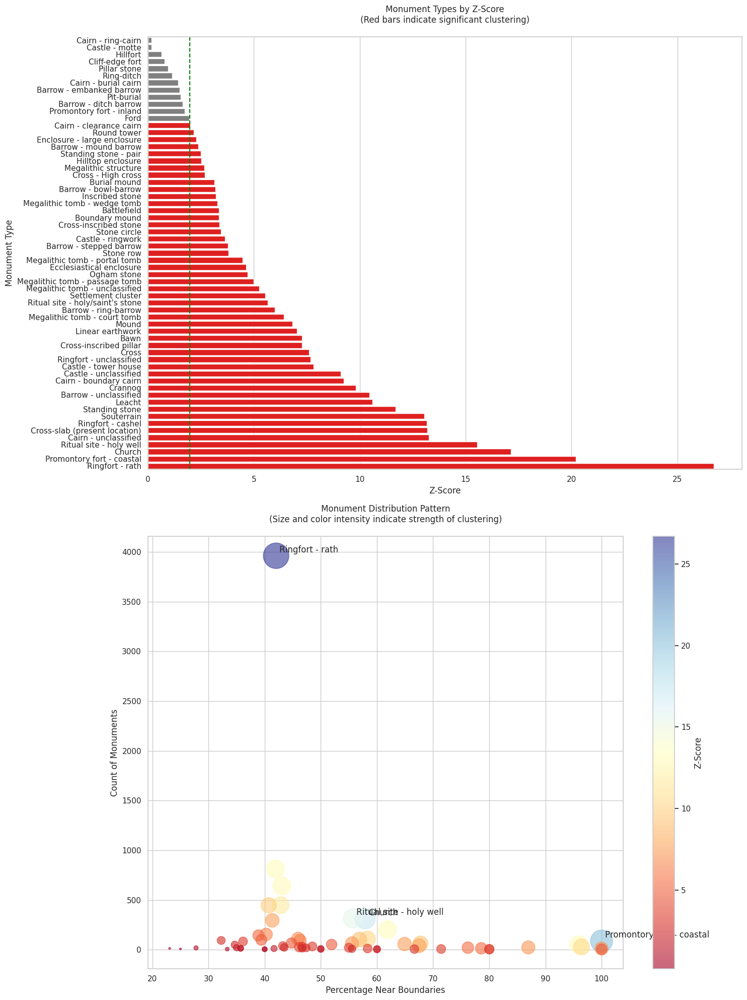


Summary of Spatial Patterns:
--------------------------------------------------
Total monument types analyzed: 61
Significantly clustered types (Z > 1.96): 49

Top 5 most strongly clustered monument types:
                  MONUMENT_T  Count  Observed_Percentage    Z_Score
0            Ringfort - rath   3961            42.034840  26.714592
1  Promontory fort - coastal     87           100.000000  20.213327
2                     Church    311            57.877814  17.134751
3    Ritual site - holy well    314            55.732484  15.538651
4       Cairn - unclassified    202            61.881188  13.253138


In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read the CSV file
df = pd.read_csv('monument_spatial_patterns.csv')

# Sort by Z-Score for better visualization
df_sorted = df.sort_values('Z_Score', ascending=True)

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 20))

# Plot 1: Z-Scores with significance threshold lines
sns.barplot(x='Z_Score', y='MONUMENT_T', data=df_sorted, ax=ax1, 
           palette=['red' if x >= 1.96 else 'gray' for x in df_sorted['Z_Score']])
ax1.axvline(x=1.96, color='green', linestyle='--', label='Significance threshold (p=0.05)')
ax1.set_title('Monument Types by Z-Score\n(Red bars indicate significant clustering)', pad=20)
ax1.set_xlabel('Z-Score')
ax1.set_ylabel('Monument Type')

# Plot 2: Percentage near boundaries vs Count (bubble plot)
scatter = ax2.scatter(df['Observed_Percentage'], df['Count'], 
                     s=df['Z_Score']*50, # Size based on Z-Score
                     alpha=0.6,
                     c=df['Z_Score'], # Color based on Z-Score
                     cmap='RdYlBu')
ax2.set_xlabel('Percentage Near Boundaries')
ax2.set_ylabel('Count of Monuments')
ax2.set_title('Monument Distribution Pattern\n(Size and color intensity indicate strength of clustering)', pad=20)

# Add colorbar
plt.colorbar(scatter, ax=ax2, label='Z-Score')

# Annotate some interesting points
for idx, row in df.iterrows():
    if row['Z_Score'] > 15 or row['Count'] > 2000:
        ax2.annotate(row['MONUMENT_T'], 
                    (row['Observed_Percentage'], row['Count']),
                    xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of Spatial Patterns:")
print("-" * 50)
print(f"Total monument types analyzed: {len(df)}")
print(f"Significantly clustered types (Z > 1.96): {len(df[df['Z_Score'] > 1.96])}")
print("\nTop 5 most strongly clustered monument types:")
print(df.nlargest(5, 'Z_Score')[['MONUMENT_T', 'Count', 'Observed_Percentage', 'Z_Score']])

In [41]:
import geopandas as gpd
import numpy as np
from shapely.geometry import Point
from scipy.stats import percentileofscore

# Load data
monuments = tuatha_nw_1600_mod
boundaries = sites_nw_clean

# Ensure CRS consistency
if monuments.crs != boundaries.crs:
    monuments = monuments.to_crs(boundaries.crs)

# Buffer boundaries by 1500 meters
boundary_buffer = boundaries.buffer(1500)

# Calculate observed percentage
monuments_within_buffer = monuments[monuments.geometry.apply(lambda x: boundary_buffer.contains(x).any())]
observed_percentage = len(monuments_within_buffer) / len(monuments) * 100

# Monte Carlo Simulation
n_simulations = 1000
random_percentages = []

for _ in range(n_simulations):
    # Generate random points within the study area
    study_area = boundaries.unary_union
    random_points = [Point(np.random.uniform(*study_area.bounds[:2]), 
                           np.random.uniform(*study_area.bounds[2:])) for _ in range(len(monuments))]
    random_gdf = gpd.GeoDataFrame(geometry=random_points, crs=monuments.crs)
    
    # Calculate percentage of random points within the buffer
    random_within_buffer = random_gdf[random_gdf.geometry.apply(lambda x: boundary_buffer.contains(x).any())]
    random_percentage = len(random_within_buffer) / len(random_gdf) * 100
    random_percentages.append(random_percentage)

# Calculate p-value
p_value = (np.sum(np.array(random_percentages) >= observed_percentage) + 1) / (n_simulations + 1)

# Print results
print(f"Observed Percentage: {observed_percentage:.2f}%")
print(f"P-value: {p_value:.4f}")

/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union
/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union
/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union
/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union
/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union
/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, us

Observed Percentage: 0.00%
P-value: 1.0000


/tmp/ipykernel_154560/4114978710.py:27: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = boundaries.unary_union


In [49]:

from pointpats import RipleyKFunction


# Convert to numpy array
monument_coords = np.array([(geom.x, geom.y) for geom in monuments.geometry])

# Define study area bounding box (assumes rectangular study area)
min_x, min_y, max_x, max_y = boundaries.total_bounds
area = (max_x - min_x) * (max_y - min_y)

# Compute support values (distances)
support = np.linspace(0, 1500, 30)

# Create Ripley K function object
rkf = RipleyKFunction(monument_coords, support, area=area)

# Plot
rkf.plot()
plt.show()


ImportError: cannot import name 'RipleyKFunction' from 'pointpats' (/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/pointpats/__init__.py)

In [ ]:
sites_nw_clean['Boundary_Intersection_Percentage'] = pd.Series(percentage_list)

# Save the percentage list as a Geodataframe series.
sites_nw_clean.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features.shp")




/tmp/ipykernel_154560/86394692.py:4: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  sites_nw_clean.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features.shp")
/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Boundary_Intersection_Percentage' to 'Boundary_I'
  ogr_write(


In [50]:
sites_nw_clean.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry', 'Boundary_Intersection_Percentage'],
      dtype='object')

In [53]:
from shapely.ops import unary_union

def buffer_object_intersection(archae_objects, buffer_distance, tuatha_nw_1600_mod):
    """
    Determines whether archaeological objects are within a certain distance of a boundary.

    Parameters:
        archae_objects (GeoDataFrame): GeoDataFrame containing archaeological objects.
        buffer_distance (float): Distance (in the same units as the GeoDataFrame) for the buffer.
        tuatha_nw_1600_mod (GeoDataFrame): GeoDataFrame containing the boundary geometries.

    Returns:
        Series: Boolean Series indicating whether each object intersects with the boundary buffer.
    """
    # Ensure CRS consistency
    if archae_objects.crs != tuatha_nw_1600_mod.crs:
        archae_objects = archae_objects.to_crs(tuatha_nw_1600_mod.crs)

    # Create a unified boundary geometry using shapely.ops.unary_union
    boundary_union = unary_union(tuatha_nw_1600_mod.geometry)

    # Create a buffer around each archaeological object
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)

    # Check for intersections with the unified boundary
    intersections = monument_buffer.intersects(boundary_union)

    return intersections

# Parameters
buffer_distance = 1500  # Adjust the buffer size as needed
monument_classes = sites_nw_clean['MONUMENT_T'].unique()

# Initialize an empty list to store intersection results
intersection_list = []

# Process each monument class
for monument_class in monument_classes:
    # Filter objects by monument class
    class_objects = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == monument_class]

    # Compute intersections
    intersections = buffer_object_intersection(class_objects, buffer_distance, tuatha_nw_1600_mod)

    # Extend the results to the intersection list
    intersection_list.extend(intersections)

# Add the intersection results as a new column in the GeoDataFrame
sites_nw_clean['Intersection'] = intersection_list

In [54]:
sites_nw_clean.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry', 'Boundary_Intersection_Percentage',
       'Intersection'],
      dtype='object')

In [56]:
# Save the percentage list as a Geodataframe series.
sites_nw_clean.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features_2.shp")

/tmp/ipykernel_154560/2249893205.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  sites_nw_clean.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features_2.shp")
/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Boundary_Intersection_Percentage' to 'Boundary_I'
  ogr_write(
/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Intersection' to 'Intersecti'
  ogr_write(


In [57]:
sites_nw_clean.head

<bound method NDFrame.head of         OID_  OBJECTID ENTITY_ID CLASS_CODE           SMRS   COUNTY  \
0       2325      2325   LE00212       BOCA  LE004-021----  LEITRIM   
1       5325      5325   LE00213       BOCA  LE004-022----  LEITRIM   
2       5326      5326   LE00214       BOCA  LE004-023----  LEITRIM   
3       7588      7588   LE00215       BOCA  LE004-024----  LEITRIM   
4      19549     19549   CV01168       BAWN  CV025-098002-    CAVAN   
...      ...       ...       ...        ...            ...      ...   
9480  162057    162057   SL07570       RATH  SL039-169----    SLIGO   
9481  162060    162060   SL07572       RATH  SL019-264001-    SLIGO   
9482  162061    162061   SL07573       SOUT  SL019-264002-    SLIGO   
9483  162073    162073   SL07578       RATH  SL034-266----    SLIGO   
9484  162383    162383   LE02706       COEN  LE035-046----  LEITRIM   

                                               TOWNLAND  COUNTY_ID  ZONE_ID  \
0                                    C

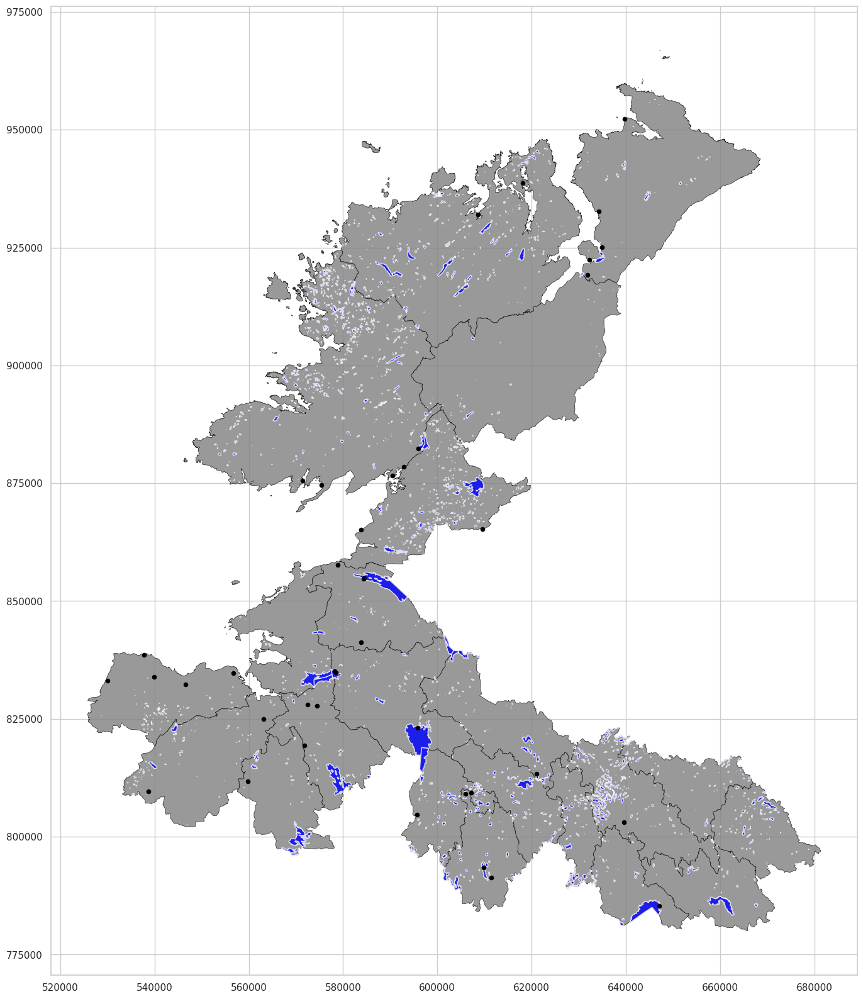

In [68]:
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='black', linewidth=0.5, alpha=0.8 )
rivers.plot(ax=ax, color='blue', markersize=1, alpha=0.8)
# Plot the 'Tower Houses' category
sites_nw_features_2 = gpd.read_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features_2.shp")
tower_houses = sites_nw_features_2[sites_nw_features_2['MONUMENT_T'] == 'Castle - tower house']
tower_houses.plot(ax=ax, color='black', markersize=20, label='Tower Houses')
plt.show()



18


FEATURE ENGINEERING -- MONUMENTS 

Categorical features based on physical characteristics, location data, predicted age.





In [ ]:
# Load the sites nw features file
# sites_nw_features = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp')

# sites_nw_features.columns
 

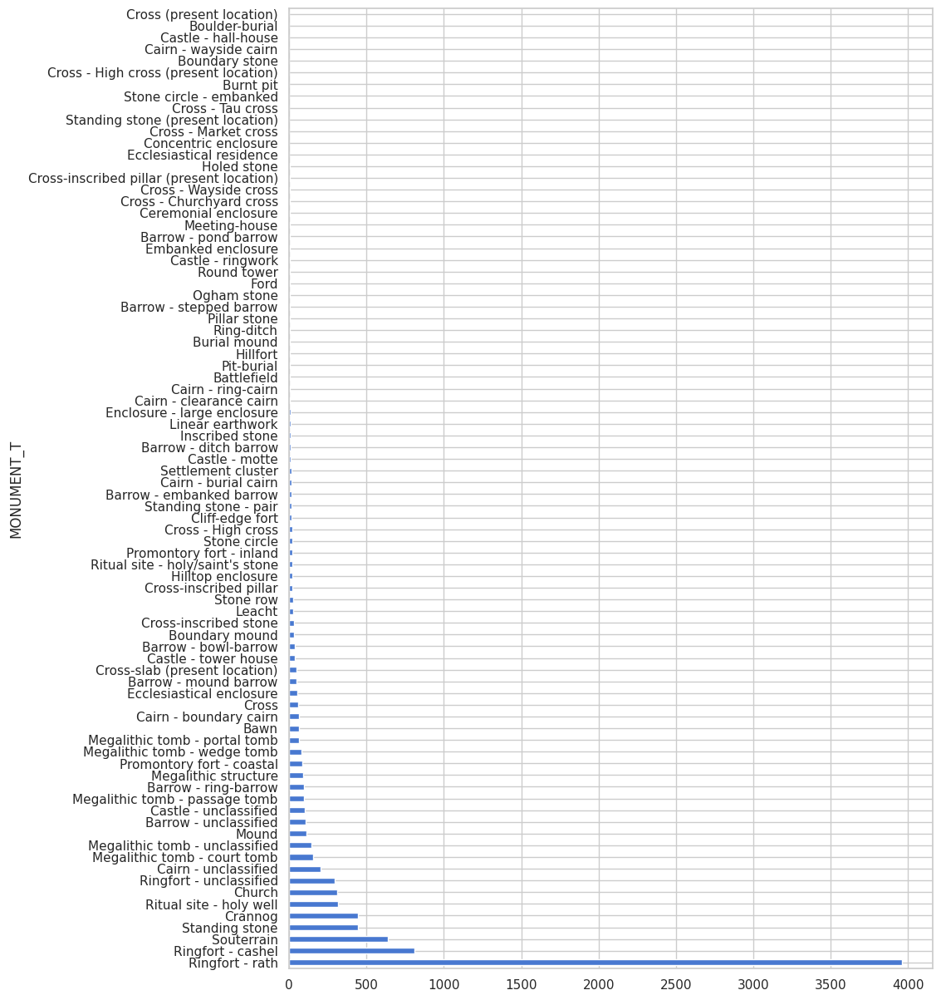

In [67]:
sites_nw_features_2['MONUMENT_T'].value_counts().plot(kind='barh', figsize=(10,15))   
plt.show()


In [69]:
mon_count = sites_nw_features_2.groupby("MONUMENT_T").MONUMENT_T.count()
print(mon_count)

with open('monument_count.txt', 'w') as f:
    f.write(mon_count.to_string())



MONUMENT_T
Barrow - bowl-barrow                 37
Barrow - ditch barrow                12
Barrow - embanked barrow             14
Barrow - mound barrow                49
Barrow - pond barrow                  4
                                     ..
Standing stone (present location)     2
Standing stone - pair                15
Stone circle                         20
Stone circle - embanked               2
Stone row                            26
Name: MONUMENT_T, Length: 82, dtype: int64


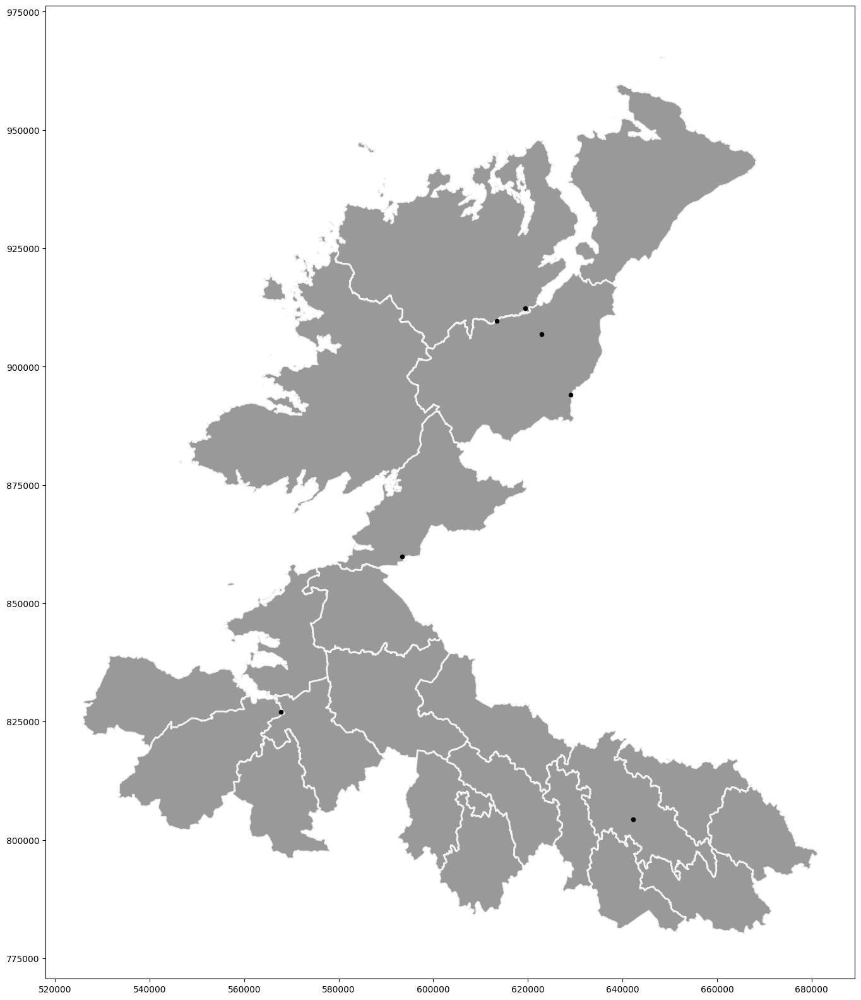

In [66]:
# Remove the following classes from the sites_nw_features file
# Meeting-house, Cross - Market cross - They are post 1600

sites_nw_features = sites_nw_features[sites_nw_features.MONUMENT_T != 'Meeting-house']
sites_nw_features = sites_nw_features[sites_nw_features.MONUMENT_T != 'Cross - Market cross']


In [70]:
# List monument types
monument_types = sites_nw_features_2['MONUMENT_T'].unique()
monument_types




array(['Cairn - boundary cairn', 'Bawn', 'Ringfort - rath', 'Church',
       'Cairn - unclassified', 'Castle - unclassified', 'Standing stone',
       'Megalithic structure', 'Crannog', 'Souterrain',
       'Megalithic tomb - portal tomb', 'Ritual site - holy well',
       'Ringfort - cashel', 'Cross', 'Ringfort - unclassified',
       'Barrow - unclassified', 'Megalithic tomb - unclassified',
       'Ring-ditch', 'Stone row', 'Megalithic tomb - court tomb', 'Mound',
       'Megalithic tomb - wedge tomb', 'Boundary mound', 'Ford',
       'Castle - tower house', 'Hilltop enclosure', 'Stone circle',
       'Promontory fort - inland', 'Megalithic tomb - passage tomb',
       'Round tower', 'Ecclesiastical enclosure',
       'Ecclesiastical residence', 'Cross-inscribed stone',
       'Ceremonial enclosure', 'Enclosure - large enclosure',
       'Cross - Market cross', 'Inscribed stone', 'Concentric enclosure',
       'Settlement cluster', 'Linear earthwork',
       "Ritual site - holy/sain

In [78]:
# Create a column called signal_medium and populate it with the material of the monument
# Define your dictionary
# Add more monument types as needed

signal_medium_dict = {
    'Cairn': 'Stone',
    'Bawn': 'Stone',  
    'Ringfort - rath': 'Earth', 
    'Church': 'Stone',
    'Castle - unclassified': 'Stone',
    'Standing stone': 'Stone',
    'Megalithic structure': 'Stone',
    'Crannog': 'Stone',
    'Souterrain': 'Stone',
    'Megalithic tomb - portal tomb'
    'Ritual site - holy well' : 'Stone',
    'Ringfort - cashel' : 'Stone',
    'Cross' : 'Stone',
    'Ringfort - unclassified' : 'Earth',
    'Barrow - unclassified' : 'Earth',
    'Megalithic tomb - unclassified' : 'Stone',  
    'Ring-ditch' : 'Earth',
    'Stone row' : 'Stone',
    'Megalithic tomb - court tomb' : 'Stone',
    'Mound' : 'Earth',
    'Megalithic tomb - wedge tomb' : 'Stone',
    'Boundary mound' : 'Earth',
    'Ford' : 'Earth',
    'Castle - tower house' : 'Stone',
    'Hilltop enclosure' : 'Earth',
    'Stone circle' : 'Stone',
    'Promontory fort - inland' : 'Earth',
    'Megalithic tomb - passage tomb' : 'Stone',
    'Round tower' : 'Stone',
    'Ecclesiastical enclosure' : 'Stone',
    'Ecclesiastical residence' : 'Stone',
    'Cross-inscribed stone' : 'Stone',
    'Ceremonial enclosure' : 'Earth',
    'Enclosure - large enclosure' : 'Earth',
    'Inscribed stone' : 'Stone',
    'Concentric enclosure' : 'Earth',
    'Settlement cluster' : 'Earth',
    'Linear earthwork' : 'Earth',
    "Ritual site - holy/saint's stone" : 'Stone',
    'Ogham stone' : 'Stone',
    'Cross - Wayside cross' : 'Stone',
    'Promontory fort - coastal' : 'Earth',
    'Cross - High cross' : 'Stone',
    'Cross - Churchyard cross' : 'Stone',
    'Holed stone' : 'Stone',
    'Castle - motte' : 'Stone',
    'Castle - ringwork' : 'Stone',
    'Burial mound' : 'Earth',
    'Cairn - burial cairn' : 'Earth',
    'Burnt pit' : 'Earth',
    'Standing stone (present location)' : 'Stone',
    'Cross-inscribed pillar' : 'Stone',
    'Pillar stone' : 'Stone',
    'Cross - Tau cross' : 'Stone',
    'Leacht' : 'Stone',
    'Cross-slab (present location)' : 'Stone',
    'Barrow - ring-barrow' : 'Earth',
    'Standing stone - pair' : 'Stone',
    'Cross-inscribed pillar (present location)' : 'Stone',
    'Pit-burial' : 'Earth',
    'Hillfort' : 'Earth',
    'Cliff-edge fort' : 'Earth',
    'Stone circle - embanked' : 'Stone',
    'Cairn - clearance cairn' : 'Stone',
    'Barrow - pond barrow' : 'Earth',
    'Cross - High cross (present location)' : 'Stone',
    'Cairn - ring-cairn' : 'Stone',
    'Cairn - wayside cairn' : 'Stone',
    'Boundary stone' : 'Stone',
    'Barrow - mound barrow' : 'Earth',
    'Barrow - stepped barrow' : 'Earth',
    'Castle - hall-house' : 'Stone',
    'Barrow - bowl-barrow' : 'Earth',
    'Barrow - embanked barrow' : 'Earth',
    'Embanked enclosure' : 'Earth',
    'Barrow - ditch barrow' : 'Earth',
    'Cross (present location)' : 'Stone',
    'Boulder-burial' : 'Stone',
    'Battlefield': 'Text',
    'Castle - tower house': 'Stone',
    'Cairn - boundary cairn': 'Stone', 
    'Cairn - unclassified': 'Stone', 
    'Megalithic tomb - portal tomb': 'Stone', 
    'Ritual site - holy well': 'Stone', 
    'Cross - Market cross': 'Stone',
    'Meeting-house': 'Stone',

}

# Create the new column
sites_nw_features_2['signal_medium'] = sites_nw_features_2['MONUMENT_T'].map(signal_medium_dict)



In [79]:
sites_nw_features_2.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry', 'signal_medium'],
      dtype='object')

In [80]:
sites_nw_features_2['signal_medium']

# lets list the null values
null_values = sites_nw_features_2[sites_nw_features_2['signal_medium'].isnull()]
null_values_list = null_values['MONUMENT_T'].unique().tolist()
print(null_values_list)


[]


In [81]:
# Load soils map data
soils_nw = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/soils_map_nw.shp')
# soils_nw.head()



In [82]:
soils_nw.head()



,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,...,ha,URL,UniqueID,DRAINAGE,TEXTURE,DEPTH,SHAPE_Leng,SHAPE_Area,SOC,geometry
0,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.696484,http://gis.teagasc.ie/soils/,2877,Poor,Peat,None,2895.714564,96964.847077,0.0,"POLYGON ((635766.844 809566.516, 635773.42 809..."
1,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,30.859582,http://gis.teagasc.ie/soils/,2887,Poor,Peat,None,8253.807654,308595.830317,0.0,"POLYGON ((634217.362 810308.775, 634285.658 81..."
2,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,None,2737.026809,97054.747857,0.0,"POLYGON ((631261.95 810589.847, 631085.879 810..."
3,29008,TULLYHUNCO,Teallach Dhúnchadha,15,An Cabhán,CAVAN,Ulster,2ae19629-11c1-13a3-e055-000000000001,629128.31,802860.29,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,None,2737.026809,97054.747857,0.0,"POLYGON ((630826.397 810700.688, 631085.879 81..."
4,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,10.334379,http://gis.teagasc.ie/soils/,2931,Poor,Peat,None,2053.385719,103343.786336,0.0,"MULTIPOLYGON (((639154.271 811760.516, 638999...."


In [83]:
# Ensure the CRS of soils_nw matches that of sites_nw_features_2
if soils_nw.crs != sites_nw_features_2.crs:
    soils_nw = soils_nw.to_crs(sites_nw_features_2.crs)

from shapely.geometry import Point

def get_soil_type(point):
    """
    Returns the soil type at a given point location.
    
    Parameters:
        point: Point geometry object representing monument location
        
    Returns:
        str: Soil texture type from the soils map, or None if no soil type found
    """
    try:
        for idx, row in soils_nw.iterrows():
            if point.within(row.geometry):
                return row['Texture_Su']
        return None
    except Exception as e:
        print(f"Error processing point: {e}")
        return None

# Apply the function to the 'geometry' column and store in 'substrate'
sites_nw_features_2['substrate'] = sites_nw_features_2['geometry'].apply(get_soil_type)

# Verify the new column
print("\nUnique soil types found:")
print(sites_nw_features_2['substrate'].value_counts(dropna=False))
print(f"\nTotal monuments: {len(sites_nw_features_2)}")
print(f"Monuments with soil type: {sites_nw_features_2['substrate'].notna().sum()}")
print(f"Monuments missing soil type: {sites_nw_features_2['substrate'].isna().sum()}")






Unique soil types found:
substrate
Fine loamy drift with limestones                          1949
Peat                                                      1447
Fine loamy drift with siliceous stones                    1285
Coarse loamy drift with limestones                        1064
Coarse loamy drift with igneous and metamorphic stones     550
Fine loamy over shale and slate bedrock                    530
Fine loamy drift with silIceous stones                     402
Clayey drift with siliceous stones                         325
Water body                                                 312
Coarse loamy drift with siliceous stones                   210
River alluvium                                             184
Peat over lithoskeletal acid igneous rock                  176
Rock                                                       156
Fine loamy over shale bedrock                              130
Urban                                                      116
Fine loamy over san

In [84]:
sites_nw_features_2.columns



Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry', 'signal_medium',
       'substrate'],
      dtype='object')

In [86]:
sites_nw_features_2['substrate'].nunique()


31

In [87]:
# Save the sites_nw_features file
sites_nw_features_2.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features_2.shp")



/tmp/ipykernel_154560/4104016377.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  sites_nw_features_2.to_file("/home/dylanf/Documents/GitHub/data/Files1600/sites_nw_features_2.shp")
/home/dylanf/Documents/GitHub/Artefact/venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'signal_medium' to 'signal_med'
  ogr_write(


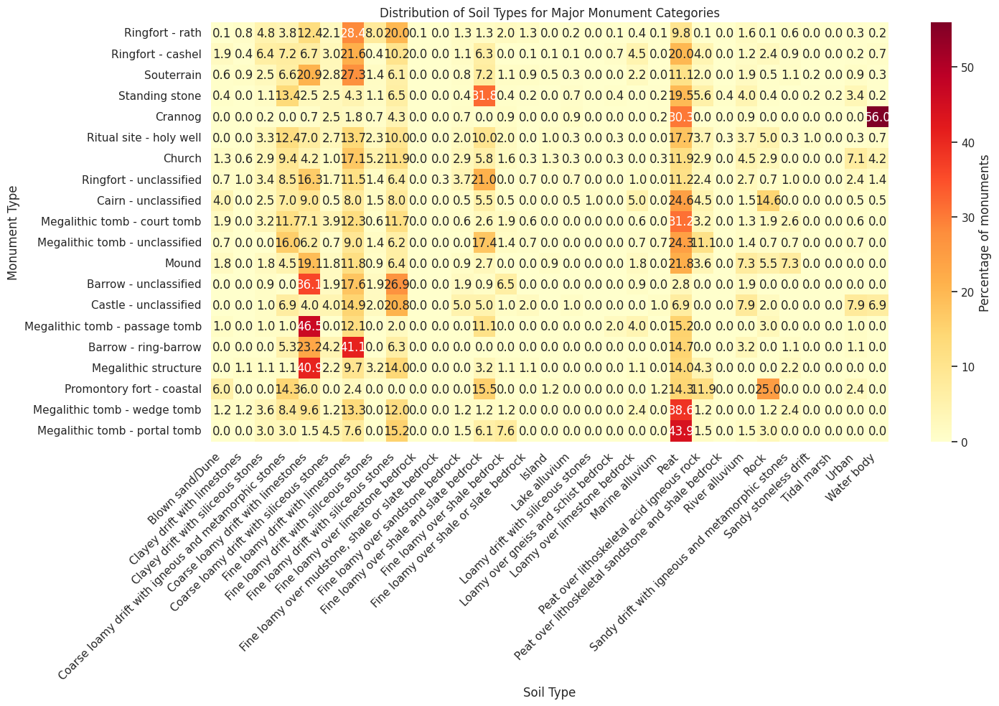


Chi-square test results:
Chi-square statistic: 17343.50
p-value: 0.0000
Degrees of freedom: 2430

Soil distribution for Ringforts:
Fine loamy drift with limestones: 1125 (28.4%)
Fine loamy drift with siliceous stones: 793 (20.0%)
Coarse loamy drift with limestones: 492 (12.4%)
Peat: 388 (9.8%)
Fine loamy drift with silIceous stones: 316 (8.0%)
Clayey drift with siliceous stones: 192 (4.8%)
Coarse loamy drift with igneous and metamorphic stones: 151 (3.8%)
Coarse loamy drift with siliceous stones: 84 (2.1%)
Fine loamy over shale bedrock: 79 (2.0%)
River alluvium: 65 (1.6%)
Fine loamy over shale or slate bedrock: 52 (1.3%)
Fine loamy over sandstone bedrock: 52 (1.3%)
Fine loamy over shale and slate bedrock: 51 (1.3%)
Clayey drift with limestones: 30 (0.8%)
Sandy drift with igneous and metamorphic stones: 23 (0.6%)
Loamy over limestone bedrock: 17 (0.4%)
Urban: 12 (0.3%)
Water body: 8 (0.2%)
Lake alluvium: 7 (0.2%)
Marine alluvium: 5 (0.1%)
Rock: 4 (0.1%)
Peat over lithoskeletal acid ign

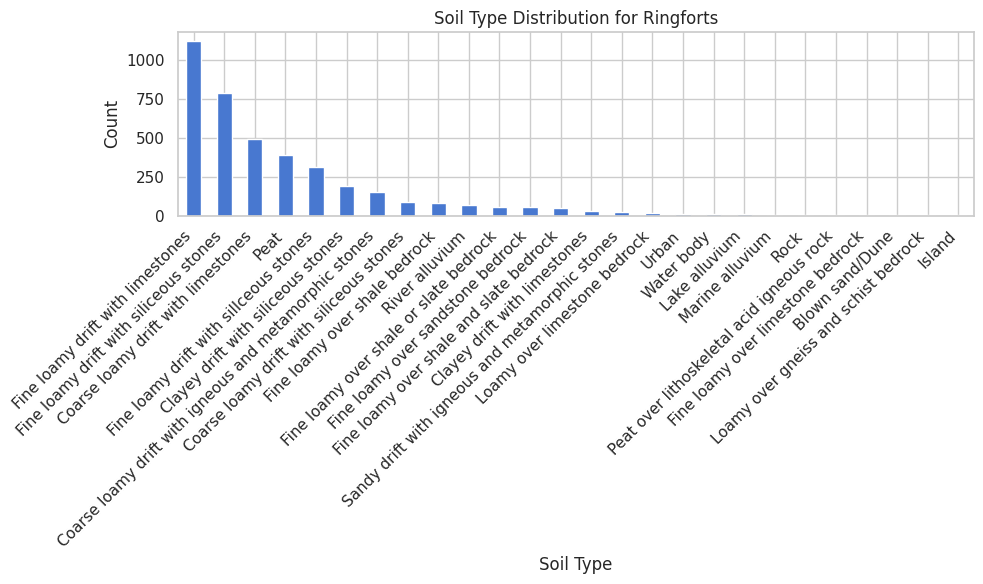

In [92]:
# 1. First, let's create a cross-tabulation of monument types and soil types
soil_monument_crosstab = pd.crosstab(sites_nw_features_2['MONUMENT_T'], 
                                    sites_nw_features_2['substrate'], 
                                    normalize='index') * 100  # Convert to percentages

# 2. Let's focus on the most common monument types (top 20)
top_monuments = sites_nw_features_2['MONUMENT_T'].value_counts().head(20).index
soil_distribution_major = soil_monument_crosstab.loc[top_monuments]

# 3. Create a heatmap visualization
plt.figure(figsize=(15, 10))
sns.heatmap(soil_distribution_major, 
            annot=True, 
            fmt='.1f',
            cmap='YlOrRd',
            cbar_kws={'label': 'Percentage of monuments'})

plt.title('Distribution of Soil Types for Major Monument Categories')
plt.ylabel('Monument Type')
plt.xlabel('Soil Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Chi-square test of independence
from scipy.stats import chi2_contingency

# Create contingency table without normalization
contingency_table = pd.crosstab(sites_nw_features_2['MONUMENT_T'], 
                               sites_nw_features_2['substrate'])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("\nChi-square test results:")
print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

# 5. For specific monument types (e.g., ringforts)
ringfort_soil = sites_nw_features_2[sites_nw_features_2['MONUMENT_T'] == 'Ringfort - rath']['substrate'].value_counts()
total_ringforts = ringfort_soil.sum()

print("\nSoil distribution for Ringforts:")
for soil_type, count in ringfort_soil.items():
    percentage = (count/total_ringforts) * 100
    print(f"{soil_type}: {count} ({percentage:.1f}%)")

# 6. Visualization for specific monument type
plt.figure(figsize=(10, 6))
ringfort_soil.plot(kind='bar')
plt.title('Soil Type Distribution for Ringforts')
plt.xlabel('Soil Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [90]:
import json

chi_square_results = {
    "chi_square_statistic": float(chi2),
    "p_value": float(p_value),
    "degrees_of_freedom": int(dof),
    "contingency_table": contingency_table.to_dict(),
    "expected_frequencies": expected.tolist()
}

# Save to file
with open('chi_square_results.json', 'w') as f:
    json.dump(chi_square_results, f, indent=4)

In [1]:
joined.columns


NameError: name 'joined' is not defined

In [93]:
tuatha_nw_1600_mod.columns

Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry', 'ID'],
      dtype='object')

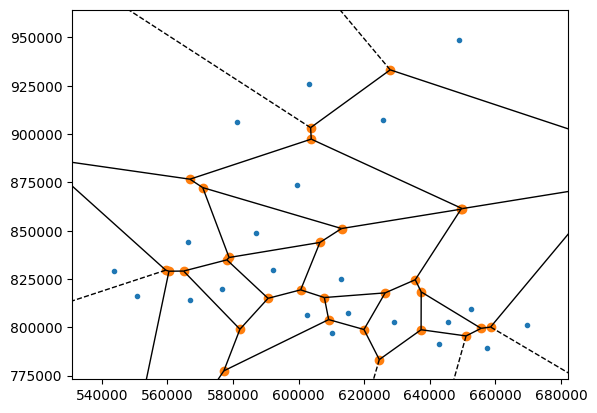

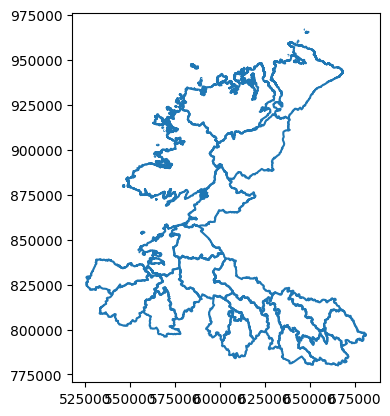

In [ ]:
# Plot a Voronoi tessellation map generated from the centroids of the polygon map


from scipy.spatial import Voronoi, voronoi_plot_2d



# Create a list of tuples where each tuple contains the x and y coordinates of a centroid
points = list(zip(tuatha_nw_1600_mod['CENTROID_X'], tuatha_nw_1600_mod['CENTROID_Y']))

# Create a Voronoi tessellation based on the centroids
vor = Voronoi(points)

# Plot the Voronoi tessellation
voronoi_plot_2d(vor)

# Overlay the original polygons on the Voronoi tessellation
tuatha_nw_1600_mod.boundary.plot()

plt.show()



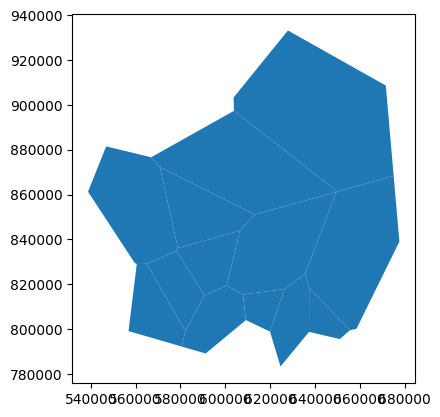

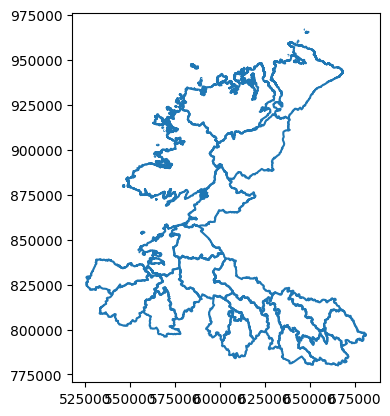

In [ ]:
from shapely.geometry import Polygon, Point

# Create a list of tuples where each tuple contains the x and y coordinates of a centroid
points = list(zip(tuatha_nw_1600_mod['CENTROID_X'], tuatha_nw_1600_mod['CENTROID_Y']))

# Create a Voronoi tessellation based on the centroids
vor = Voronoi(points)

# Create a polygon from the boundary of the original map
boundary_poly = tuatha_nw_1600_mod.unary_union.convex_hull

# Create an empty GeoDataFrame to store the Voronoi polygons
voronoi_gdf = gpd.GeoDataFrame(columns=['geometry'])

# For each Voronoi region
for region in vor.regions:
    if not -1 in region and len(region) > 0:
        # Create a polygon for the region and intersect it with the boundary
        region_poly = Polygon([vor.vertices[i] for i in region])
        intersection = boundary_poly.intersection(region_poly)
        
        # Add the intersection to the GeoDataFrame
        new_row = gpd.GeoDataFrame({'geometry': [intersection]}, crs=voronoi_gdf.crs)
        voronoi_gdf = pd.concat([voronoi_gdf, new_row], ignore_index=True)

# Plot the Voronoi polygons
voronoi_gdf.plot()

# Overlay the original polygons
tuatha_nw_1600_mod.boundary.plot()

plt.show()

Spatial Point Analysis. 
Analyse the point pattern of the data. This will help us understand the spatial distribution of the data. We can use the following methods to analyse the point pattern of the data:
- Ripley's K function
- Moran's I
- Geary's C
- L function    


In [ ]:
from pointpats import (
    distance_statistics,
    QStatistic,
    random,
    PointPattern,
)

In [ ]:
# Convert the x.y coords to an array.
# Extract x and y coordinates from the 'geometry' column
raths_coords = [(point.x, point.y) for point in raths.geometry]

# Create a PointPattern object
raths_points = PointPattern(raths_coords)

Point Pattern
3961 points
Bounding rectangle [(19550,19550), (162073,162073)]
Area of window: 20312805529.0
Intensity estimate for window: 1.9500014384251331e-07
       x      y   mark_0 mark_1         mark_2 mark_3  \
5  19550  19550  CV01169   RATH  CV025-099----  CAVAN   
6  19559  19559  CV01155   RATH  CV025-087----  CAVAN   
7  19560  19560  CV01156   RATH  CV025-088----  CAVAN   
8  19563  19563  CV01159   RATH  CV025-090----  CAVAN   
9  19564  19564  CV01160   RATH  CV025-092----  CAVAN   

                    mark_4  mark_5   mark_6  mark_7  mark_8     mark_9  \
5  NEWTOWN (Clanmahon By.)       3  R168132  636873  799493  53.943449   
6          LISMORE DEMESNE       3  R168161  637053  800272  53.950436   
7          LISMORE DEMESNE       3  R168156  637103  800132  53.949174   
8              LISNAMANDRA       3  R170277  637883  801992  53.965831   
9            LOUGHACONNICK       3  R170259  640162  801642  53.962514   

    mark_10          mark_11 mark_12   mark_13  \


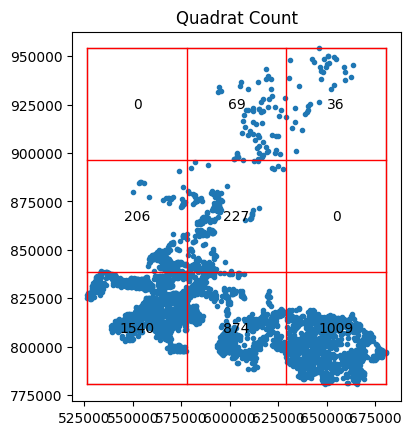

In [ ]:
# Apply QStatistic to the PointPattern object
raths_points = PointPattern(raths)
raths_points.summary()

qstat.plot()
plt.show()

# Create a PointPattern object
# Plot the QStatistic




pointpats.pointpattern.PointPattern

In [ ]:
from pointpats import PointPattern
from pysal.explore.pointpats import K, PoissonPointProcess, Window
import numpy as np
import matplotlib.pyplot as plt

# Define the study area as a rectangle
min_x, min_y, max_x, max_y = raths.geometry.total_bounds
window = Window([[(min_x, min_y), (min_x, max_y), (max_x, max_y), (max_x, min_y), (min_x, min_y)]])

# Generate a Poisson Point Process for comparison
ppp = PoissonPointProcess(window, len(raths_points.points), 100, asPP=True)

# Compute the K-function
k_real = K(raths_points.points)
k_rand = K(ppp.realizations[0].points)

# Compute the distances for the K-function
distances = np.linspace(0, max_x - min_x, 100)

# Compute the K-function values for the real and random data
k_real_values = [k_real.function(d) for d in distances]
k_rand_values = [k_rand.function(d) for d in distances]

# Plot the K-function
plt.figure()
plt.plot(distances, k_real_values, label='Real')
plt.plot(distances, k_rand_values, label='Random')
plt.legend()
plt.title('K-function')
plt.show()

/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/spaghetti/network.py:40: FutureWarning: The next major release of pysal/spaghetti (2.0.0) will drop support for all ``libpysal.cg`` geometries. This change is a first step in refactoring ``spaghetti`` that is expected to result in dramatically reduced runtimes for network instantiation and operations. Users currently requiring network and point pattern input as ``libpysal.cg`` geometries should prepare for this simply by converting to ``shapely`` geometries.
  warnings.warn(dep_msg, FutureWarning, stacklevel=1)


ImportError: cannot import name 'K' from 'pysal.explore.pointpats' (/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/pysal/explore/pointpats/__init__.py)

In [ ]:
from pointpats import K, G, PoissonPointProcess, Window
import matplotlib.pyplot as plt

# Define the study area as a rectangle
min_x, min_y, max_x, max_y = raths.geometry.total_bounds
window = Window([[(min_x, min_y), (min_x, max_y), (max_x, max_y), (max_x, min_y), (min_x, min_y)]])

# Generate a Poisson Point Process for comparison
ppp = PoissonPointProcess(window, len(raths_points.points), 100, asPP=True)

# Compute the K-function
k_real = K(raths_points, window=window)
k_rand = K(ppp, window=window)

# Compute the G-function
g_real = G(raths_points, window=window)
g_rand = G(ppp, window=window)

# Plot the K-function
plt.figure()
plt.plot(k_real[0], k_real[1], label='Real')
plt.plot(k_rand[0], k_rand[1], label='Random')
plt.legend()
plt.title('K-function')
plt.show()

# Plot the G-function
plt.figure()
plt.plot(g_real[0], g_real[1], label='Real')
plt.plot(g_rand[0], g_rand[1], label='Random')
plt.legend()
plt.title('G-function')
plt.show()

ImportError: cannot import name 'K' from 'pointpats' (/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/pointpats/__init__.py)

In [ ]:
#




18


In [ ]:
raths['cluster']

KeyError: 'cluster'

NameError: name 'clusters' is not defined

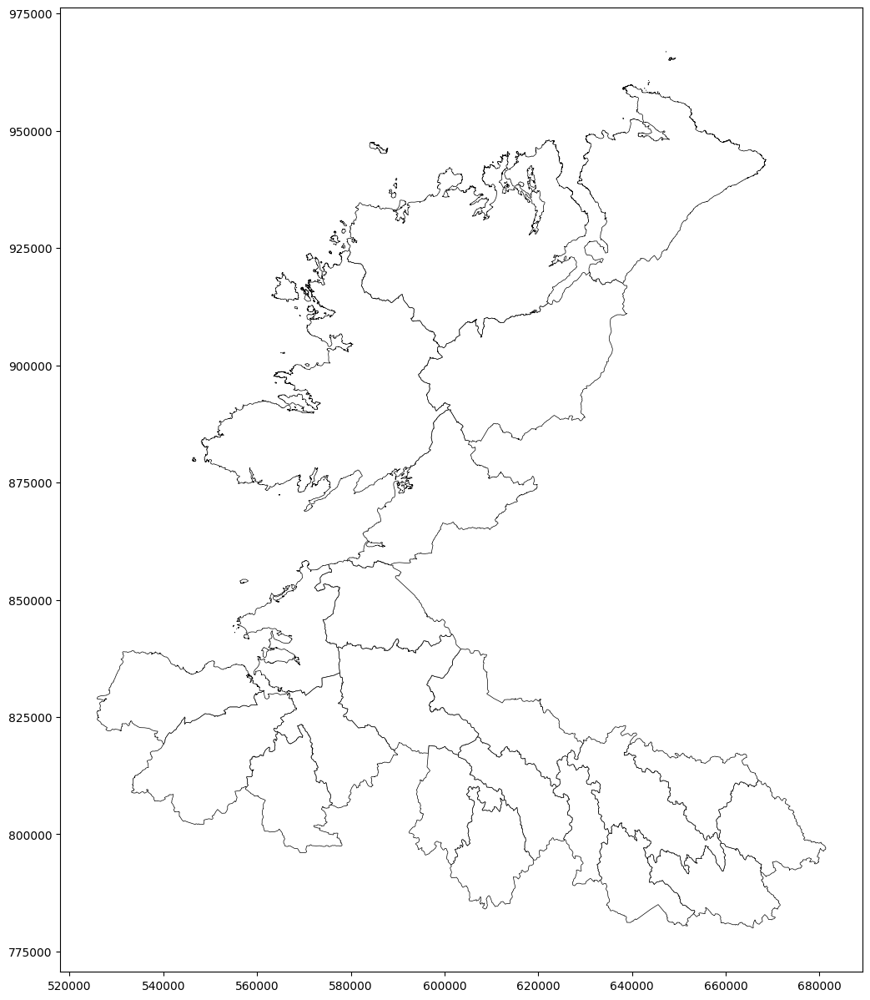

In [ ]:
# Setup figure and axis
f, ax = plt.subplots(1, figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, zorder=1)


# Subset points that are not part of any cluster (noise)
noise = raths.loc[clusters == -1, ["x", "y"]]

# Plot noise in grey
ax.scatter(noise["x"], noise["y"], c="grey", s=5, linewidth=0, zorder=2)

# Plot all points that are not noise in red
# NOTE this is done through some fancy indexing, where
#      we take the index of all points (db) and substract from
#      it the index of those that are noise
ax.scatter(
    raths.loc[raths.index.difference(noise.index), "x"],
    raths.loc[raths.index.difference(noise.index), "y"],
    c="red",
    linewidth=0,
)

# Remove axes
ax.set_axis_off()
# Display the figure
plt.show()

In [ ]:
sites_nw_clean.info

<bound method DataFrame.info of         OID_  OBJECTID ENTITY_ID CLASS_CODE           SMRS   COUNTY  \
0       2325      2325   LE00212       BOCA  LE004-021----  LEITRIM   
1       5325      5325   LE00213       BOCA  LE004-022----  LEITRIM   
2       5326      5326   LE00214       BOCA  LE004-023----  LEITRIM   
3       7588      7588   LE00215       BOCA  LE004-024----  LEITRIM   
4      19549     19549   CV01168       BAWN  CV025-098002-    CAVAN   
...      ...       ...       ...        ...            ...      ...   
9480  162057    162057   SL07570       RATH  SL039-169----    SLIGO   
9481  162060    162060   SL07572       RATH  SL019-264001-    SLIGO   
9482  162061    162061   SL07573       SOUT  SL019-264002-    SLIGO   
9483  162073    162073   SL07578       RATH  SL034-266----    SLIGO   
9484  162383    162383   LE02706       COEN  LE035-046----  LEITRIM   

                                               TOWNLAND  COUNTY_ID  ZONE_ID  \
0                                   

0       Marked only on the 1910 ed. of the OS 6-inch m...
1       Marked only on the 1910 ed. of the OS 6-inch m...
2       Marked only on the 1910 ed. of the OS 6-inch m...
3       Marked only on the 1910 ed. of the OS 6-inch m...
4       Davies (1948a, 115) recorded the site of a pla...
                              ...                        
9480    In pasture, on the level top of a low hill/dru...
9481    In good coastal grassland, 1km S of Ballysadar...
9482    In a rath (SL019-264001-), close to the NE arc...
9483    In rough, rush-grown upland pasture, located o...
9484    Reported by Jean-Charles Caillere; visible on ...
Name: WEB_NOTES, Length: 9485, dtype: object

bank 4731
area 4719
int 3927
circular 3906
diam 3599
wth 3577
5m 2904
circular area 2825
enclosed 2644
earthen 2627
pasture 2615
raised 2475
fosse 2452
situated 2363
stone 2224
earthen bank 2208
slope 2132
facing 2094
se 2059
ne 2015
os 1975
sw 1969
low 1956
nw 1936
area int 1857


In [94]:
# Sample WEB_NOTES entries that have the word diam or wth in them

# Create a list of words/phrases to search for
search_words = ['diam' 'area int']

# Create a list of indices where the search words/phrases are found
search_indices = []
for i, note in enumerate(sites_nw_clean['WEB_NOTES']):
    if any(word in note for word in search_words):
        search_indices.append(i)

# Display sample entries based on the found indices
sample_entries = sites_nw_clean.loc[search_indices, 'WEB_NOTES']
print(sample_entries)

Series([], Name: WEB_NOTES, dtype: object)


In [95]:
sample_entries.iloc[9477]

IndexError: single positional indexer is out-of-bounds

IndexError: single positional indexer is out-of-bounds

In [ ]:
# Use regex to extract both "diam" and "wth" and their respective diameters

pattern_diam = r'diam(?:eter)?\s*([\d.]+)'
pattern_wth = r'wth(?:\s*is)?\s*([\d.]+)'

sites_nw_clean['Diameter_diam'] = sites_nw_clean['WEB_NOTES'].str.extract(pattern_diam, flags=re.IGNORECASE)
sites_nw_clean['Diameter_wth'] = sites_nw_clean['WEB_NOTES'].str.extract(pattern_wth, flags=re.IGNORECASE)




In [ ]:
#  Convert the 'Diameter_diam' and 'Diameter_wth' columns to numeric (float) type

sites_nw_clean['Diameter_diam'] = pd.to_numeric(sites_nw_clean['Diameter_diam'], errors='coerce')
sites_nw_clean['Diameter_wth'] = pd.to_numeric(sites_nw_clean['Diameter_wth'], errors='coerce')



In [ ]:
# Sum the diameter values from "diam" and "wth" and create a new 'Diameter' column
sites_nw_clean['Diameter'] = sites_nw_clean['Diameter_diam'] + sites_nw_clean['Diameter_wth']


# Replace NaN values in 'Diameter' with 0
sites_nw_clean['Diameter'].fillna(0, inplace=True)

In [ ]:
# Drop the intermediate columns
sites_nw_clean.drop(columns=['Diameter_diam', 'Diameter_wth'], inplace=True)


In [ ]:
# Display the result
sites_nw_clean['Diameter']

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
9480    0.0
9481    0.0
9482    0.0
9483    0.0
9484    0.0
Name: Diameter, Length: 9485, dtype: float64

In [ ]:
# Create a function to find words in a text, or import those ive alreafy written


def find_words(text):
    words_to_find = ['univallate', 'bivallate','trivallate','bi-vallate', 'tri-vallate', 'single ditch', 'double ditch', 'triple ditch', 'single bank', 'double bank', 'triple bank', 'single rampart', 'double rampart', 'triple rampart', 'triple enclosure']
    found_words = [word for word in words_to_find if word in text]
    return ', '.join(found_words)


# Apply the function to create a new column 'found_words'
sites_nw_clean['found_words'] = sites_nw_clean['WEB_NOTES'].apply(find_words)

In [ ]:
sites_nw_clean['found_words'].value_counts()

In [ ]:
# find row with 'trivallate' in 'found_words' column
trivallate = sites_nw_clean[sites_nw_clean['found_words'] == 'trivallate']
trivallate.head()

In [ ]:
pd.DataFrame(filtered_points_2['MONUMENT_T'].value_counts()).plot.bar(width=0.5, figsize=(15,6))
plt.show()